# AIC 2026 — Sơ tuyển 2: Hybrid CLIP + metadata + temporal + visual review

Bản này tái sử dụng index 177.321 keyframe/873 video, nhưng **không lặp lại cách nộp P1**.

1. Retrieval dùng prompt ngắn có trọng số, chuẩn hóa percentile theo từng prompt, title prior và temporal rerank.
2. Ảnh keyframe được đọc trực tiếp từ 14 ZIP để bạn xác minh top 1/5/20.
3. Có helper tải riêng một MP4 chính thức để chốt QA/TRAKE, không tải cả 83 GB.
4. Submission P2 được tách hoàn toàn khỏi P1 và chỉ tạo sau khi đủ 9 QA + token xác nhận.

Chạy **Runtime → Run all**. Sau batch, đổi `REVIEW_QUERY_ID` và chạy lại hai cell review.


In [ ]:
# 1) Cài thư viện — không train model
%pip install -q 'faiss-cpu==1.15.0' ftfy regex tqdm pillow matplotlib rapidfuzz remotezip pytesseract
%pip install -q 'git+https://github.com/openai/CLIP.git@dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1'


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 73.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 62.5 MB/s eta 0:00:00:00:01
  Preparing metadata (setup.py) ... done


In [ ]:
# 2) Kết nối Drive và khai báo đường dẫn
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from urllib.parse import parse_qsl, urlencode, urlsplit, urlunsplit
import csv
import hashlib
import io
import json
import os
import re
import shutil
import zipfile

import faiss
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from tqdm.auto import tqdm

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('Hãy mở notebook bằng Google Colab.') from exc

drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/AIC2026')
RAW_DIR = DRIVE_ROOT / 'raw'
INDICES_DIR = DRIVE_ROOT / 'indices'
CANDIDATES_DIR = DRIVE_ROOT / 'candidates'
SUBMISSION_DIR = DRIVE_ROOT / 'submission'
MODELS_DIR = DRIVE_ROOT / 'models'
WORK_DIR = Path('/content/aic_work')
KEYFRAME_ZIP_DIR = DRIVE_ROOT / 'keyframe_zips'
P2_CANDIDATES_DIR = CANDIDATES_DIR / 'p2'
P2_SUBMISSION_ROOT = SUBMISSION_DIR / 'p2'
SELECTED_VIDEOS_DIR = DRIVE_ROOT / 'selected_videos'

for directory in (INDICES_DIR, P2_CANDIDATES_DIR, P2_SUBMISSION_ROOT, MODELS_DIR, SELECTED_VIDEOS_DIR, WORK_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CORE_ARCHIVES = {
    'features': {
        'filename': 'clip-features-32-aic25-b1.zip',
        'expected_bytes': 168_173_583,
        'outer': 'clip-features-32-aic25-b1',
        'inner': 'clip-features-32',
        'suffix': '.npy',
    },
    'maps': {
        'filename': 'map-keyframes-aic25-b1.zip',
        'expected_bytes': 1_604_272,
        'outer': 'map-keyframes-aic25-b1',
        'inner': 'map-keyframes',
        'suffix': '.csv',
    },
    'media': {
        'filename': 'media-info-aic25-b1.zip',
        'expected_bytes': 1_111_755,
        'outer': 'media-info-aic25-b1',
        'inner': 'media-info',
        'suffix': '.json',
    },
}

print('Drive:', DRIVE_ROOT)
print('Runtime:', WORK_DIR)
print('Device cho CLIP:', 'cuda' if torch.cuda.is_available() else 'cpu')


Mounted at /content/drive
Drive: /content/drive/MyDrive/AIC2026
Runtime: /content/aic_work
Device cho CLIP: cpu


In [ ]:
# 3) Khôi phục dữ liệu vào /content nếu Colab vừa khởi động lại
def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

def safe_extract(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    destination_root = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        bad_member = archive.testzip()
        if bad_member is not None:
            raise RuntimeError(f'ZIP lỗi CRC tại: {bad_member}')
        for member in archive.infolist():
            member_path = (destination / member.filename).resolve()
            if member_path != destination_root and destination_root not in member_path.parents:
                raise RuntimeError(f'ZIP chứa đường dẫn không an toàn: {member.filename}')
        archive.extractall(destination)

def ensure_extracted(spec):
    drive_zip = RAW_DIR / spec['filename']
    if not drive_zip.is_file():
        raise FileNotFoundError(
            f'Thiếu {drive_zip}. Hãy chạy AIC_2026_Drive_Setup.ipynb trước.'
        )
    actual_size = drive_zip.stat().st_size
    if actual_size != spec['expected_bytes']:
        raise RuntimeError(
            f"Sai dung lượng {drive_zip.name}: {actual_size:,}; "
            f"cần {spec['expected_bytes']:,} bytes"
        )
    archive_sha256 = sha256_file(drive_zip)

    work_root = WORK_DIR.resolve()
    destination = (WORK_DIR / spec['outer']).resolve()
    if destination == work_root or work_root not in destination.parents:
        raise RuntimeError(f'Thư mục giải nén không an toàn: {destination}')
    inner_dir = destination / spec['inner']
    marker_path = destination / '.extract_complete.json'
    existing = list(inner_dir.glob(f"*{spec['suffix']}")) if inner_dir.is_dir() else []
    marker = {}
    if marker_path.is_file():
        try:
            with open(marker_path, encoding='utf-8') as file:
                marker = json.load(file)
        except (OSError, json.JSONDecodeError):
            marker = {}
    if (
        len(existing) == 873
        and marker.get('archive_sha256') == archive_sha256
        and marker.get('file_count') == 873
        and marker.get('suffix') == spec['suffix']
    ):
        print(f"✓ Tái sử dụng {len(existing)} file tại {inner_dir}")
        return inner_dir, archive_sha256

    local_zip = WORK_DIR / spec['filename']
    local_zip_valid = (
        local_zip.is_file()
        and local_zip.stat().st_size == actual_size
        and sha256_file(local_zip) == archive_sha256
    )
    if not local_zip_valid:
        print(f'→ Copy {drive_zip.name} xuống runtime...')
        shutil.copy2(drive_zip, local_zip)
    if destination.exists():
        print(f'→ Làm sạch cache giải nén cũ: {destination}')
        shutil.rmtree(destination)
    print(f'→ Giải nén {local_zip.name}...')
    safe_extract(local_zip, destination)

    extracted = list(inner_dir.glob(f"*{spec['suffix']}"))
    if len(extracted) != 873:
        raise RuntimeError(f'{inner_dir} chỉ có {len(extracted)} file; cần 873.')
    with open(marker_path, 'w', encoding='utf-8', newline='\n') as file:
        json.dump({
            'archive': spec['filename'],
            'archive_sha256': archive_sha256,
            'file_count': len(extracted),
            'suffix': spec['suffix'],
        }, file, ensure_ascii=False, indent=2)
    print(f'✓ Hoàn tất: {inner_dir}')
    return inner_dir, archive_sha256

FEATURE_DIR, feature_archive_sha = ensure_extracted(CORE_ARCHIVES['features'])
MAP_DIR, map_archive_sha = ensure_extracted(CORE_ARCHIVES['maps'])
MEDIA_DIR, media_archive_sha = ensure_extracted(CORE_ARCHIVES['media'])
EXTRACTED_ARCHIVE_HASHES = {
    'features': feature_archive_sha,
    'maps': map_archive_sha,
    'media': media_archive_sha,
}


→ Copy clip-features-32-aic25-b1.zip xuống runtime...
→ Giải nén clip-features-32-aic25-b1.zip...
✓ Hoàn tất: /content/aic_work/clip-features-32-aic25-b1/clip-features-32
→ Copy map-keyframes-aic25-b1.zip xuống runtime...
→ Giải nén map-keyframes-aic25-b1.zip...
✓ Hoàn tất: /content/aic_work/map-keyframes-aic25-b1/map-keyframes
→ Copy media-info-aic25-b1.zip xuống runtime...
→ Giải nén media-info-aic25-b1.zip...
✓ Hoàn tất: /content/aic_work/media-info-aic25-b1/media-info


In [ ]:
# 4) Kiểm tra ba bộ file khớp tuyệt đối theo video_id
feature_files = {path.stem: path for path in FEATURE_DIR.glob('*.npy')}
map_files = {path.stem: path for path in MAP_DIR.glob('*.csv')}
media_files = {path.stem: path for path in MEDIA_DIR.glob('*.json')}

feature_ids = set(feature_files)
map_ids = set(map_files)
media_ids = set(media_files)
if feature_ids != map_ids or feature_ids != media_ids:
    raise RuntimeError(
        'Ba bộ dữ liệu không khớp video_id.\n'
        f'NPY thiếu so với tổng hợp: {sorted((map_ids | media_ids) - feature_ids)[:10]}\n'
        f'CSV thiếu: {sorted((feature_ids | media_ids) - map_ids)[:10]}\n'
        f'JSON thiếu: {sorted((feature_ids | map_ids) - media_ids)[:10]}'
    )
if len(feature_ids) != 873:
    raise RuntimeError(f'Tìm thấy {len(feature_ids)} video; bộ này phải có 873 video.')

VIDEO_IDS = sorted(feature_ids)

archive_hashes = dict(EXTRACTED_ARCHIVE_HASHES)
print('✓ Checksum ba ZIP nguồn đã được xác nhận cùng cache giải nén.')

source_lines = [
    f'{video_id}|{feature_files[video_id].stat().st_size}|'
    f'{map_files[video_id].stat().st_size}|{media_files[video_id].stat().st_size}'
    for video_id in VIDEO_IDS
]
source_lines += [f'archive|{key}|{archive_hashes[key]}' for key in sorted(archive_hashes)]
SOURCE_FINGERPRINT = hashlib.sha256('\n'.join(source_lines).encode('utf-8')).hexdigest()
group_counts = Counter(video_id.split('_', 1)[0] for video_id in VIDEO_IDS)

print(f'✓ {len(VIDEO_IDS)} video có đủ NPY + CSV + JSON')
print('Các nhóm:', dict(sorted(group_counts.items())))
print('Source fingerprint:', SOURCE_FINGERPRINT[:16] + '…')


✓ Checksum ba ZIP nguồn đã được xác nhận cùng cache giải nén.
✓ 873 video có đủ NPY + CSV + JSON
Các nhóm: {'L21': 29, 'L22': 31, 'L23': 25, 'L24': 43, 'L25': 88, 'L26': 498, 'L27': 16, 'L28': 24, 'L29': 23, 'L30': 96}
Source fingerprint: e8354abe69c43359…


In [ ]:
# 5) Dựng hoặc tải lại exact cosine index
DIMENSION = 512
EXPECTED_VIDEOS = 873
CHUNK_ROWS = 32_768
BUNDLE_VERSION = 'aic25_b1_clip_vit_b32_ip_v1'
FORCE_REBUILD = False  # đổi thành True chỉ khi muốn dựng lại index

LOCAL_INDEX_DIR = WORK_DIR / 'indices'
LOCAL_INDEX_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_INDEX = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}.faiss'
LOCAL_FRAMES = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_frames.csv.gz'
LOCAL_VIDEOS = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_videos.csv'
LOCAL_MANIFEST = LOCAL_INDEX_DIR / f'{BUNDLE_VERSION}_manifest.json'
DRIVE_INDEX = INDICES_DIR / LOCAL_INDEX.name
DRIVE_FRAMES = INDICES_DIR / LOCAL_FRAMES.name
DRIVE_VIDEOS = INDICES_DIR / LOCAL_VIDEOS.name
DRIVE_MANIFEST = INDICES_DIR / LOCAL_MANIFEST.name

def numeric_integer_array(series, label):
    values = pd.to_numeric(series, errors='raise').to_numpy(dtype=np.float64)
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f'{label} phải gồm các số nguyên hữu hạn.')
    return values.astype(np.int64)

def validate_sources():
    required_columns = {'n', 'pts_time', 'fps', 'frame_idx'}
    total_rows = 0
    dtypes = set()
    row_counts = {}
    for video_id in tqdm(VIDEO_IDS, desc='Kiểm tra NPY ↔ CSV'):
        embeddings = np.load(feature_files[video_id], mmap_mode='r', allow_pickle=False)
        if embeddings.ndim != 2 or embeddings.shape[1] != DIMENSION:
            raise ValueError(f'{video_id}: shape NPY sai {embeddings.shape}; cần (N, 512).')
        if not np.issubdtype(embeddings.dtype, np.floating):
            raise TypeError(f'{video_id}: dtype NPY không phải số thực: {embeddings.dtype}')
        mapping = pd.read_csv(map_files[video_id])
        missing = required_columns - set(mapping.columns)
        if missing:
            raise ValueError(f'{video_id}: CSV thiếu cột {sorted(missing)}')
        if len(mapping) != embeddings.shape[0]:
            raise ValueError(
                f'{video_id}: NPY có {embeddings.shape[0]} dòng nhưng CSV có {len(mapping)} dòng.'
            )
        keyframe_n = numeric_integer_array(mapping['n'], f'{video_id}.n')
        frame_idx = numeric_integer_array(mapping['frame_idx'], f'{video_id}.frame_idx')
        pts_time = pd.to_numeric(mapping['pts_time'], errors='raise').to_numpy(dtype=np.float64)
        fps = pd.to_numeric(mapping['fps'], errors='raise').to_numpy(dtype=np.float64)
        if len(np.unique(keyframe_n)) != len(keyframe_n):
            raise ValueError(f'{video_id}: cột n bị trùng.')
        expected_n = np.arange(1, len(mapping) + 1, dtype=np.int64)
        if not np.array_equal(keyframe_n, expected_n):
            raise ValueError(f'{video_id}: cột n phải đúng 1..N theo thứ tự dòng NPY.')
        if np.any(np.diff(keyframe_n) < 0) or np.any(np.diff(frame_idx) < 0):
            raise ValueError(f'{video_id}: n hoặc frame_idx không tăng theo thứ tự dòng.')
        if np.any(frame_idx < 0):
            raise ValueError(f'{video_id}: frame_idx âm.')
        if not np.isfinite(pts_time).all() or np.any(pts_time < 0):
            raise ValueError(f'{video_id}: pts_time không hợp lệ.')
        if not np.isfinite(fps).all() or np.any(fps <= 0):
            raise ValueError(f'{video_id}: fps không hợp lệ.')
        row_counts[video_id] = int(embeddings.shape[0])
        total_rows += int(embeddings.shape[0])
        dtypes.add(str(embeddings.dtype))
    return total_rows, row_counts, sorted(dtypes)

def read_media_table():
    rows = []
    for video_id in VIDEO_IDS:
        with open(media_files[video_id], encoding='utf-8-sig') as file:
            info = json.load(file)
        rows.append({
            'video_id': video_id,
            'group': video_id.split('_', 1)[0],
            'title': info.get('title', ''),
            'author': info.get('author', ''),
            'length': info.get('length', ''),
            'watch_url': info.get('watch_url', ''),
        })
    return pd.DataFrame(rows)

def validate_loaded_bundle(index, frames, manifest, videos=None):
    if manifest.get('bundle_version') != BUNDLE_VERSION:
        raise ValueError('Sai bundle_version.')
    if manifest.get('source_fingerprint') != SOURCE_FINGERPRINT:
        raise ValueError('Index không được dựng từ đúng bộ dữ liệu hiện tại.')
    if manifest.get('source_archive_sha256') != archive_hashes:
        raise ValueError('Checksum ZIP nguồn trong manifest không khớp.')
    if manifest.get('model') != 'openai/CLIP ViT-B/32':
        raise ValueError('Sai model trong manifest.')
    if manifest.get('clip_commit') != 'dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1':
        raise ValueError('Sai CLIP commit trong manifest.')
    if manifest.get('metric') != 'inner_product_on_l2_normalized_vectors':
        raise ValueError('Sai metric trong manifest.')
    if manifest.get('dimension') != DIMENSION or not manifest.get('normalized'):
        raise ValueError('Sai dimension hoặc quy ước normalize trong manifest.')
    if index.d != DIMENSION or index.ntotal != len(frames):
        raise ValueError('Số chiều/số dòng giữa FAISS và metadata không khớp.')
    if manifest.get('total_vectors') != len(frames) or manifest.get('video_count') != EXPECTED_VIDEOS:
        raise ValueError('Số vector/video trong manifest không khớp.')
    required_frame_columns = {
        'faiss_id', 'video_id', 'group', 'npy_row',
        'keyframe_n', 'frame_idx', 'pts_time', 'fps',
    }
    missing_columns = required_frame_columns - set(frames.columns)
    if missing_columns:
        raise ValueError(f'Metadata frame thiếu cột: {sorted(missing_columns)}')
    expected_ids = np.arange(len(frames), dtype=np.int64)
    actual_ids = frames['faiss_id'].to_numpy(dtype=np.int64)
    if not np.array_equal(expected_ids, actual_ids):
        raise ValueError('faiss_id trong metadata không liên tục từ 0.')
    numeric_columns = ['keyframe_n', 'frame_idx', 'pts_time', 'fps']
    if not np.isfinite(frames[numeric_columns].to_numpy(dtype=np.float64)).all():
        raise ValueError('Metadata frame chứa NaN/Inf.')
    if videos is not None:
        if len(videos) != EXPECTED_VIDEOS or videos['video_id'].duplicated().any():
            raise ValueError('Metadata video thiếu hoặc trùng video_id.')
        if set(videos['video_id']) != set(VIDEO_IDS):
            raise ValueError('Danh sách video trong metadata không khớp nguồn.')

def load_bundle_from_drive():
    required = (DRIVE_INDEX, DRIVE_FRAMES, DRIVE_VIDEOS, DRIVE_MANIFEST)
    if not all(path.is_file() for path in required):
        return None
    with open(DRIVE_MANIFEST, encoding='utf-8') as file:
        manifest = json.load(file)
    if manifest.get('source_fingerprint') != SOURCE_FINGERPRINT:
        raise ValueError('Fingerprint nguồn đã thay đổi.')

    pairs = (
        (DRIVE_INDEX, LOCAL_INDEX, 'index'),
        (DRIVE_FRAMES, LOCAL_FRAMES, 'frames'),
        (DRIVE_VIDEOS, LOCAL_VIDEOS, 'videos'),
    )
    for drive_path, local_path, key in pairs:
        print(f'→ Copy {drive_path.name} xuống runtime...')
        shutil.copy2(drive_path, local_path)
        expected_hash = manifest['sha256'][key]
        if sha256_file(local_path) != expected_hash:
            raise ValueError(f'Checksum sai: {drive_path.name}')

    # Chỉ đọc FAISS sau khi checksum của file đã đúng.
    index = faiss.read_index(str(LOCAL_INDEX))
    frames = pd.read_csv(LOCAL_FRAMES)
    videos = pd.read_csv(LOCAL_VIDEOS, keep_default_na=False)
    validate_loaded_bundle(index, frames, manifest, videos)
    print(f'✓ Đã tải index: {index.ntotal:,} vector, {index.d} chiều')
    return index, frames, videos, manifest

def build_bundle():
    total_rows, row_counts, source_dtypes = validate_sources()
    estimated_mib = total_rows * DIMENSION * 4 / (1024 ** 2)
    print(f'Tổng keyframe embedding: {total_rows:,}')
    print(f'RAM/file index float32 ước tính: {estimated_mib:,.1f} MiB')

    index = faiss.IndexFlatIP(DIMENSION)
    frame_parts = []
    row_spans = []
    cursor = 0

    for video_id in tqdm(VIDEO_IDS, desc='Dựng FAISS exact index'):
        embeddings = np.load(feature_files[video_id], mmap_mode='r', allow_pickle=False)
        mapping = pd.read_csv(map_files[video_id])
        rows = len(mapping)
        start_id = cursor

        for start in range(0, rows, CHUNK_ROWS):
            end = min(start + CHUNK_ROWS, rows)
            block = np.ascontiguousarray(embeddings[start:end], dtype=np.float32)
            if not np.isfinite(block).all():
                raise ValueError(f'{video_id}: embedding chứa NaN/Inf.')
            norms = np.linalg.norm(block, axis=1)
            if np.any(norms <= 1e-12):
                raise ValueError(f'{video_id}: embedding có vector zero.')
            faiss.normalize_L2(block)
            index.add(block)

        keyframe_n = numeric_integer_array(mapping['n'], f'{video_id}.n')
        frame_idx = numeric_integer_array(mapping['frame_idx'], f'{video_id}.frame_idx')
        pts_time = pd.to_numeric(mapping['pts_time'], errors='raise').to_numpy(dtype=np.float64)
        fps = pd.to_numeric(mapping['fps'], errors='raise').to_numpy(dtype=np.float64)
        if not np.isfinite(pts_time).all() or not np.isfinite(fps).all():
            raise ValueError(f'{video_id}: pts_time/fps chứa NaN/Inf.')

        frame_parts.append(pd.DataFrame({
            'faiss_id': np.arange(cursor, cursor + rows, dtype=np.int64),
            'video_id': video_id,
            'group': video_id.split('_', 1)[0],
            'npy_row': np.arange(rows, dtype=np.int32),
            'keyframe_n': keyframe_n,
            'frame_idx': frame_idx,
            'pts_time': pts_time,
            'fps': fps,
        }))
        cursor += rows
        row_spans.append({
            'video_id': video_id,
            'start': start_id,
            'end': cursor,
            'rows': rows,
        })

    frames = pd.concat(frame_parts, ignore_index=True)
    videos = read_media_table()
    if index.ntotal != total_rows or len(frames) != total_rows:
        raise RuntimeError('Số vector và metadata không khớp sau khi build.')

    probe_ids = np.array([0, total_rows // 2, total_rows - 1], dtype=np.int64)
    probes = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in probe_ids]),
        dtype=np.float32,
    )
    probe_scores, nearest = index.search(probes, 1)
    # Không bắt buộc ID trả về giống probe: hai frame có thể có vector trùng nhau.
    if np.any(nearest[:, 0] < 0) or not np.allclose(probe_scores[:, 0], 1.0, atol=1e-4):
        raise RuntimeError('Self-neighbor smoke test thất bại: cosine không gần 1.')

    faiss.write_index(index, str(LOCAL_INDEX))
    frames.to_csv(LOCAL_FRAMES, index=False, compression='gzip')
    videos.to_csv(LOCAL_VIDEOS, index=False, encoding='utf-8')
    manifest = {
        'bundle_version': BUNDLE_VERSION,
        'built_at_utc': datetime.now(timezone.utc).isoformat(),
        'model': 'openai/CLIP ViT-B/32',
        'clip_commit': 'dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1',
        'dimension': DIMENSION,
        'metric': 'inner_product_on_l2_normalized_vectors',
        'normalized': True,
        'index_dtype': 'float32',
        'source_dtypes': source_dtypes,
        'mapping_convention': 'NPY row i maps to CSV row i; n=i+1; submit frame_idx',
        'video_count': len(VIDEO_IDS),
        'total_vectors': total_rows,
        'source_fingerprint': SOURCE_FINGERPRINT,
        'source_archive_sha256': archive_hashes,
        'row_spans': row_spans,
        'versions': {
            'faiss': getattr(faiss, '__version__', 'unknown'),
            'numpy': np.__version__,
            'pandas': pd.__version__,
            'torch': torch.__version__,
        },
        'sha256': {
            'index': sha256_file(LOCAL_INDEX),
            'frames': sha256_file(LOCAL_FRAMES),
            'videos': sha256_file(LOCAL_VIDEOS),
        },
    }
    with open(LOCAL_MANIFEST, 'w', encoding='utf-8', newline='\n') as file:
        json.dump(manifest, file, ensure_ascii=False, indent=2)

    for local_path, drive_path in (
        (LOCAL_INDEX, DRIVE_INDEX),
        (LOCAL_FRAMES, DRIVE_FRAMES),
        (LOCAL_VIDEOS, DRIVE_VIDEOS),
    ):
        print(f'→ Lưu {local_path.name} lên Drive...')
        shutil.copy2(local_path, drive_path)
    # Manifest được ghi cuối cùng như dấu hiệu bundle đã hoàn tất.
    shutil.copy2(LOCAL_MANIFEST, DRIVE_MANIFEST)
    print(f'✓ Đã lưu bundle tại {INDICES_DIR}')
    return index, frames, videos, manifest

bundle = None
if not FORCE_REBUILD:
    try:
        bundle = load_bundle_from_drive()
    except Exception as exc:
        print(f'⚠ Không dùng được index đã lưu: {exc}')
        print('Sẽ dựng lại từ dữ liệu nguồn.')
if bundle is None:
    bundle = build_bundle()

index, frame_metadata, video_metadata, build_manifest = bundle
validate_loaded_bundle(index, frame_metadata, build_manifest, video_metadata)
print(f'READY: {index.ntotal:,} keyframes từ {len(video_metadata):,} video')


→ Copy aic25_b1_clip_vit_b32_ip_v1.faiss xuống runtime...
→ Copy aic25_b1_clip_vit_b32_ip_v1_frames.csv.gz xuống runtime...
→ Copy aic25_b1_clip_vit_b32_ip_v1_videos.csv xuống runtime...
✓ Đã tải index: 177,321 vector, 512 chiều
READY: 177,321 keyframes từ 873 video


## Ngân hàng truy vấn P2


In [ ]:
# 6) Ngân hàng 30 truy vấn Sơ tuyển 2 — prompt nguyên tử, có trọng số
QUERY_BANK = {'p2-1': {'task': 'kis',
          'query_vi': 'Nhóm 5 người đang chơi đùa bên cạnh một con vật màu vàng. Một trong số đó đã mang một '
                      'vật trông như trái bí đỏ đi giấu. Người đàn ông thức dậy không thấy quả bí đỏ đâu nên '
                      'đánh thức con vật dậy.',
          'parts_en': ['five people play beside a large yellow animal costume',
                       'a person secretly hides an orange pumpkin',
                       'a man wakes up and shakes the yellow animal awake'],
          'part_weights': [1.0, 1.35, 1.2],
          'title_hints': ['bí đỏ', 'con vật màu vàng', 'múa lân'],
          'temporal': True},
 'p2-2': {'task': 'kis',
          'query_vi': 'Đoạn clip bắt đầu với cảnh một người đang dùng điện thoại chụp ảnh bức tranh hình tê '
                      'giác trên tường. Đoạn clip kết thúc với cảnh một người chụp ảnh các hình graffiti 3 '
                      'chú khỉ trên một cây cầu',
          'parts_en': ['a person uses a phone to photograph rhinoceros graffiti on a wall',
                       'graffiti of three monkeys painted on a bridge'],
          'part_weights': [1.15, 1.35],
          'title_hints': ['graffiti', 'tranh tường', 'nghệ thuật đường phố'],
          'temporal': True},
 'p2-3': {'task': 'kis',
          'query_vi': 'Một chú lân (hay rồng/sư tử?) màu vàng nhảy hay rơi từ trên cao xuống, gần với mô '
                      'hình chiếc tàu thủy nhỏ màu xanh dương.',
          'parts_en': ['a yellow lion dance costume jumps down from high poles',
                       'a yellow dragon or lion performer beside a small blue model ship'],
          'part_weights': [1.0, 1.45],
          'title_hints': ['múa lân', 'lân sư rồng', 'tàu thủy'],
          'temporal': False},
 'p2-4': {'task': 'kis',
          'query_vi': 'Hai bạn trẻ đang treo băng-rôn lớn có tông màu xanh dương, được trang trí bằng hình '
                      'ảnh núi, mây và một con đường dẫn tới trường học. Trên băng rôn còn có hình ảnh 02 em '
                      'bé vùng khó khăn đang mặc áo màu vàng.',
          'parts_en': ['two young people hang a large blue charity school banner',
                       'a blue banner shows mountains clouds a road to school and two children in yellow '
                       'shirts'],
          'part_weights': [1.0, 1.45],
          'title_hints': ['đến trường', 'trẻ em vùng cao', 'thiện nguyện'],
          'temporal': False},
 'p2-5': {'task': 'kis',
          'query_vi': 'Một người áo đỏ, đội nón màu trắng, đang lấy nước rưới vào mặt của mình. Khung hình '
                      'có hai người đi xe đạp, người mặc áo xanh đậm đang đuổi theo người mặc áo đen phối '
                      'cam.',
          'parts_en': ['a cyclist in a red shirt and white cap splashes water on his face',
                       'a dark blue cyclist chases a cyclist wearing black and orange'],
          'part_weights': [1.35, 1.1],
          'title_hints': ['đua xe đạp', 'xe đạp'],
          'temporal': False},
 'p2-6': {'task': 'kis',
          'query_vi': 'Đoạn video do người đi đường phía sau ghi lại cho thấy 2 thanh niên điều khiển xe máy '
                      'bất ngờ nằm dài trên yên và phóng với tốc độ cao. Xuất hiện trong khung hình còn có '
                      'một chiếc ô tô màu xanh cùng một người đi xe máy mặc áo xanh khác. Có 2 vòng tròn màu '
                      'đỏ xuất hiện để khoanh vùng vị trí 2 thanh niên này.',
          'parts_en': ['two motorcycle riders lie flat on their seats while speeding on a road',
                       'red circles highlight two dangerous motorcycle stunt riders near a blue car'],
          'part_weights': [1.2, 1.45],
          'title_hints': ['nằm dài trên xe', 'quái xế', 'xe máy'],
          'temporal': False},
 'p2-7': {'task': 'qa',
          'query_vi': 'Đoạn clip được quay từ bên trong một chiếc xe ô tô tự lái, có thể thấy rõ vô lăng '
                      'được xoay để chiếc xe rẽ sang phải. Sau đó, góc quay chuyển ra ngoài, bắt trọn cảnh '
                      'chiếc xe màu trắng rẽ trái, và ở góc trên khung hình có một dưới một biển hiệu đỏ gồm '
                      '6 ký tự chữ Hán. Con số được viết trên phần hông xe màu trắng là số mấy?',
          'parts_en': ['inside an autonomous car the steering wheel turns by itself',
                       'a white self driving car turns with a large number printed on its side',
                       'a white car turns below a red sign with six Chinese characters'],
          'part_weights': [0.9, 1.55, 1.1],
          'title_hints': ['xe tự lái', 'ô tô tự lái', 'autonomous car'],
          'temporal': True,
          'question_vi': 'Con số được viết trên phần hông xe màu trắng là số mấy?',
          'review_mode': 'manual_ocr_or_visual'},
 'p2-8': {'task': 'trake',
          'query_vi': 'Video về một khu vườn cây ăn trái ở miền Tây Nam Bộ. Đây là chuỗi liên tiếp các cảnh '
                      'quay về 4 loại trái cây trong vườn.\n'
                      'E1: Cảnh đầu tiên có trái sầu riêng.\n'
                      'E2: Cảnh đầu tiên có trái măng cụt.\n'
                      'E3: Cảnh đầu tiên có trái bưởi.\n'
                      'E4: Cảnh đầu tiên có trái dâu bòn bon.',
          'parts_en': ['a tropical fruit orchard in the Mekong Delta',
                       'a garden tour shows durian mangosteen pomelo and langsat fruit'],
          'part_weights': [0.8, 1.25],
          'title_hints': ['vườn trái cây', 'miền Tây', 'sầu riêng', 'măng cụt'],
          'temporal': False,
          'events_en': {'E1': 'the first shot where durian fruit is visible in the orchard',
                        'E2': 'the first shot where purple mangosteen fruit is visible',
                        'E3': 'the first shot where pomelo or grapefruit fruit is visible',
                        'E4': 'the first shot where langsat duku or lanzones fruit is visible'},
          'events_vi': {'E1': 'Cảnh đầu tiên có trái sầu riêng.',
                        'E2': 'Cảnh đầu tiên có trái măng cụt.',
                        'E3': 'Cảnh đầu tiên có trái bưởi.',
                        'E4': 'Cảnh đầu tiên có trái dâu bòn bon.'},
          'event_weights': [1.25, 1.25, 1.25, 1.25]},
 'p2-9': {'task': 'qa',
          'query_vi': 'Trong video hướng dẫn nấu ăn, người đầu bếp lần lượt cho các loại hương liệu gồm tiêu '
                      'xanh, lá chanh và sả vào bên trong bụng của tổng cộng 4 con cá. Đây là loài cá gì?',
          'parts_en': ['four whole fish are stuffed with green peppercorns kaffir lime leaves and lemongrass',
                       'a chef prepares whole seasoned fish for cooking'],
          'part_weights': [1.5, 0.8],
          'title_hints': ['cá', 'tiêu xanh', 'lá chanh', 'sả', 'món ngon mỗi ngày'],
          'temporal': False,
          'question_vi': 'Đây là loài cá gì?',
          'review_mode': 'manual_ocr_or_visual'},
 'p2-10': {'task': 'kis',
           'query_vi': 'Một đầu bếp chế biến món ăn trong chảo, với các miếng dồi trường màu trắng và rau '
                       'xanh.\n'
                       'Đầu bếp cho bông hẹ vào chảo đang có dồi trường rồi dùng dụng cụ đảo các nguyên '
                       'liệu.\n'
                       'Các đoạn bông hẹ dài màu xanh được trộn cùng những miếng dồi trường trắng trong '
                       'chảo.\n'
                       'Máy quay chuyển sang cận cảnh chảo khi đầu bếp tiếp tục xào và trộn hai nguyên liệu.',
           'parts_en': ['white pork intestines are stir fried with long green garlic chives in a wok',
                        'a chef adds flower chives to white pork intestines and tosses the wok',
                        'close up of white intestine pieces mixed with long green chives'],
           'part_weights': [1.35, 1.2, 1.15],
           'title_hints': ['dồi trường', 'bông hẹ', 'món ngon mỗi ngày'],
           'temporal': True},
 'p2-11': {'task': 'kis',
           'query_vi': 'Trong video, người đầu bếp cầm một nguyên liệu dài đã được xiên que và lăn qua hỗn '
                       'hợp màu xanh lá cây và màu đỏ đã băm nhỏ.\n'
                       'Nguyên liệu sau đó được chuyển sang một đĩa chứa bột trắng để phủ bên ngoài.\n'
                       'Người đầu bếp cầm que xiên và xoay nguyên liệu qua lại nhiều lần trên lớp bột.\n'
                       'Cuối cùng, nguyên liệu đã được phủ kín một lớp bột trắng và đặt riêng sang một chiếc '
                       'đĩa.',
           'parts_en': ['a long skewered ingredient is rolled in finely chopped red and green herbs',
                        'a cook rotates a skewer repeatedly to coat it in white flour',
                        'the flour coated skewer is placed on a separate plate'],
           'part_weights': [1.4, 1.35, 0.9],
           'title_hints': ['xiên que', 'lăn bột', 'món ngon mỗi ngày'],
           'temporal': True},
 'p2-12': {'task': 'qa',
           'query_vi': 'Đoạn video mô tả quá trình làm bánh, bánh được tạo ra có màu tím, nguyên liệu bên '
                       'trong có giá, cà rốt, và bên trong mỗi bánh đều có 1 hạt sen. Mỗi lần khuôn này làm '
                       'được bao nhiêu cái bánh?',
           'parts_en': ['purple savory cakes cook in a round multi cavity mold',
                        'purple cakes are filled with bean sprouts carrot and one lotus seed each',
                        'a full cake mold shows how many purple cakes are made at once'],
           'part_weights': [1.1, 1.3, 1.55],
           'title_hints': ['bánh màu tím', 'hạt sen', 'khuôn bánh'],
           'temporal': False,
           'question_vi': 'Mỗi lần khuôn này làm được bao nhiêu cái bánh?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-13': {'task': 'kis',
           'query_vi': 'Người đầu bếp đảo đều một hỗn hợp các nguyên liệu trong chảo, nhìn bằng mắt thường '
                       'có thể thấy một số nguyên liệu như thịt gà, ớt đỏ, ớt xanh, đậu phộng và hành tím. '
                       'Sau đó cô ấy tắt lửa, cho thêm vỏ chanh và nước cốt chanh vào chảo trước khi trút '
                       'hỗn hợp thức ăn này ra đĩa.',
           'parts_en': ['a woman chef stir fries chicken red chili green chili peanuts and shallots',
                        'the chef turns off the heat then adds lime zest and lime juice to the wok',
                        'the finished chicken peanut stir fry is poured onto a plate'],
           'part_weights': [1.15, 1.5, 0.85],
           'title_hints': ['thịt gà', 'đậu phộng', 'chanh', 'món ngon mỗi ngày'],
           'temporal': True},
 'p2-14': {'task': 'kis',
           'query_vi': 'Cận cảnh một nhóm 3 vận động viên đua xe đạp đang di chuyển sát nhau, hai tay đua '
                       'mặc áo xanh biển đội mũ bảo hiểm đỏ và trắng, bên cạnh có một tay đua mặc áo vàng '
                       'đang đua cùng. Bên dưới quai mũ của tay đua nón đỏ có một sợi dây màu trắng treo '
                       'lủng xuống gần cổ.',
           'parts_en': ['close up of three racing cyclists side by side two in blue jerseys and one in '
                        'yellow',
                        'the cyclist with a red helmet has a loose white strap hanging below his chin'],
           'part_weights': [1.0, 1.65],
           'title_hints': ['đua xe đạp', 'tay đua', 'áo vàng'],
           'temporal': False},
 'p2-15': {'task': 'kis',
           'query_vi': 'Cảnh phim lần lượt giới thiệu các nguyên liệu của món ăn qua 3 chuyển cảnh: máy quay '
                       'chéo lên và kết thúc ở nguyên liệu hải sản đầu tiên; quay từ trên xuống cận cảnh '
                       'nguyên liệu hải sản thứ hai rồi chuyển sang các nguyên liệu nhiều màu sắc; cuối cùng '
                       'là cú máy tĩnh toàn cảnh toàn bộ nguyên liệu.',
           'parts_en': ['a camera pans diagonally across seafood ingredients for a cooking recipe',
                        'top down close up of a second seafood ingredient beside colorful vegetables',
                        'a static wide overhead shot shows all colorful ingredients together'],
           'part_weights': [1.1, 1.3, 1.0],
           'title_hints': ['hải sản', 'nguyên liệu', 'món ngon mỗi ngày'],
           'temporal': True},
 'p2-16': {'task': 'kis',
           'query_vi': 'Trong một ngôi nhà nông thôn có cửa sổ lớn, hai người phụ nữ đang làm thủ công trên '
                       'một bộ ván ngựa, phía sau là một dãy khoảng 10 thớt gỗ được treo thành một hàng '
                       'ngang.',
           'parts_en': ['two women make handicrafts on a wooden platform bed inside a rural house',
                        'about ten round wooden chopping boards hang in one horizontal row behind them'],
           'part_weights': [1.0, 1.5],
           'title_hints': ['thủ công', 'thớt gỗ', 'làng nghề'],
           'temporal': False},
 'p2-17': {'task': 'kis',
           'query_vi': 'Sân khấu với dòng chữ nổi 3D to, ánh kim phủ kim tuyến có nội dung: “SẮC CỔ ...” đặt '
                       'ở mép trước sân khấu.',
           'parts_en': ['a stage has huge glittering metallic three dimensional Vietnamese letters',
                        'large sparkling letters reading SAC CO stand at the front edge of a performance '
                        'stage'],
           'part_weights': [0.9, 1.6],
           'title_hints': ['Sắc Cổ', 'sân khấu', 'nghệ thuật'],
           'temporal': False},
 'p2-18': {'task': 'kis',
           'query_vi': 'Đoạn phim quay từ phía sau nhóm dẫn đầu, gồm 1 tay đua dẫn trước và 3 tay đua bám '
                       'phía sau, khi cả nhóm rẽ phải vào đường Hồ Tùng Mậu tại giao lộ có đèn xanh đang đếm '
                       'ngược đến 13 giây.',
           'parts_en': ['rear view of four leading cyclists turning right at an intersection',
                        'cyclists turn onto Ho Tung Mau street under a green traffic light counting down '
                        'thirteen'],
           'part_weights': [1.0, 1.6],
           'title_hints': ['Hồ Tùng Mậu', 'đua xe đạp', 'chặng đua'],
           'temporal': True},
 'p2-19': {'task': 'qa',
           'query_vi': 'Đoạn phim ghi lại cảnh mạnh thường quân hỗ trợ một quán trọ dành cho người cao tuổi, '
                       'sau đó chuyển sang cảnh một cụ ông trò chuyện với nhóm người nước ngoài. Hỏi quán '
                       'trọ được nhắc đến trong đoạn phim nằm trên đường nào?',
           'parts_en': ['charity donors visit and support a lodging house for elderly people',
                        'an elderly Vietnamese man talks with a group of foreign visitors',
                        'a sign or caption gives the street address of the elderly lodging house'],
           'part_weights': [1.1, 0.95, 1.55],
           'title_hints': ['quán trọ người cao tuổi', 'mạnh thường quân', 'người cao tuổi'],
           'temporal': True,
           'question_vi': 'Quán trọ được nhắc đến trong đoạn phim nằm trên đường nào?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-20': {'task': 'kis',
           'query_vi': 'Clip bài giảng môn Địa lí, có 1 bảng số liệu về mạng lưới đô thị ở Việt Nam. Bảng '
                       'này thể hiện sự khác nhau về phân bố đô thị giữa các vùng bằng màu sắc: 3 vùng có '
                       'nhiều đô thị nhất thì con số thể hiện số lượng đô thị được in màu đỏ, còn 2 vùng có '
                       'ít đô thị nhất thì con số này được in màu xanh. Từ bảng số liệu ta còn có thể thấy '
                       'rằng vùng có ít đô thị nhất lại là vùng có dân số đô thi cao nhất.',
           'parts_en': ['a geography lecture slide contains a table about the urban network of regions in '
                        'Vietnam',
                        'city counts in a table are colored red for the three highest and blue for the two '
                        'lowest',
                        'the region with the fewest cities has the highest urban population'],
           'part_weights': [1.25, 1.45, 1.0],
           'title_hints': ['Địa lý', 'mạng lưới đô thị', 'đô thị Việt Nam'],
           'temporal': False},
 'p2-21': {'task': 'trake',
           'query_vi': '4 cảnh này xảy ra liên tiếp nhau. \n'
                       'Cảnh 1: Hai người phụ nữ cùng nhau dán niêm phong một thùng carton.\n'
                       'Cảnh 2: Các thùng mì tôm và bọc bánh mì được sắp xếp ngay ngắn.\n'
                       'Cảnh 3: Một người đàn ông nhấc thùng mì tôm lên và xếp lên trên chồng thùng mì.\n'
                       'Cảnh 4: Cảnh quay cận cảnh các thùng mì được xếp chồng trên xe tải.',
           'parts_en': ['charity aid supplies include cartons of instant noodles and bags of bread',
                        'people load stacked food cartons onto a truck'],
           'part_weights': [1.1, 1.1],
           'title_hints': ['mì tôm', 'bánh mì', 'thùng hàng', 'hỗ trợ'],
           'temporal': False,
           'events_en': {'E1': 'two women together seal a cardboard carton with tape',
                         'E2': 'cartons of instant noodles and bags of bread are neatly arranged',
                         'E3': 'a man lifts an instant noodle carton and stacks it on other cartons',
                         'E4': 'a close up shows stacked instant noodle cartons on a truck'},
           'events_vi': {'E1': 'Hai người phụ nữ cùng nhau dán niêm phong một thùng carton.',
                         'E2': 'Các thùng mì tôm và bọc bánh mì được sắp xếp ngay ngắn.',
                         'E3': 'Một người đàn ông nhấc thùng mì tôm và xếp lên chồng thùng.',
                         'E4': 'Cận cảnh các thùng mì được xếp chồng trên xe tải.'},
           'event_weights': [1.25, 1.25, 1.25, 1.25]},
 'p2-22': {'task': 'kis',
           'query_vi': 'Trong video nấu ăn, một loại nguyên liệu hải sản màu trắng được khứa theo những '
                       'đường thẳng vuông góc nhau, trên cả 2 bề mặt của nguyên liệu này. Nguyên liệu sau đó '
                       'được cắt thành từng que và cho vào tô, trước khi được trộn đều với các gia vị gồm '
                       'rượu, tiêu và hạt nêm.',
           'parts_en': ['white squid or cuttlefish is scored in a crosshatch pattern on both sides',
                        'the scored seafood is cut into sticks and placed in a bowl',
                        'seafood sticks are mixed with rice wine pepper and seasoning powder'],
           'part_weights': [1.55, 1.1, 1.2],
           'title_hints': ['mực', 'khứa', 'rượu', 'hạt nêm', 'món ngon mỗi ngày'],
           'temporal': True},
 'p2-23': {'task': 'qa',
           'query_vi': 'Câu hỏi môn Sinh học nằm ở số thứ tự 11 trong đề thi THPTQG 2022. Trong câu hỏi có '
                       'một biểu đồ đưa ra sự so sánh tốc độ sinh trưởng của các loài thực vật trong các hệ '
                       'sinh thái ven biển. Hãy cho biết loài cây (II) đạt được tốc độ sinh trưởng tốt nhất '
                       'khi môi trường sống có độ mặn là bao nhiêu phần nghìn?',
           'parts_en': ['a biology lecture slide shows question eleven from the 2022 national high school '
                        'exam',
                        'a graph compares coastal plant growth rate against salinity in parts per thousand',
                        'the graph line labeled plant II reaches its maximum growth rate'],
           'part_weights': [1.35, 1.5, 1.55],
           'title_hints': ['Sinh học', 'THPT 2022', 'hệ sinh thái ven biển', 'độ mặn'],
           'temporal': False,
           'question_vi': 'Loài cây (II) đạt tốc độ sinh trưởng tốt nhất ở độ mặn bao nhiêu phần nghìn?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-24': {'task': 'kis',
           'query_vi': 'Đoạn clip ghi lại khoảnh khắc về đích của một chặng đua xe đạp diễn ra tại thành phố '
                       'thuộc tỉnh Quảng Nam (cũ, trước ngày 01/7/2025). Vận động viên người Estonia mặc áo '
                       'xanh nước biển dẫn đầu đoàn. Khi chỉ còn cách đích một đoạn ngắn, anh buông cả hai '
                       'tay khỏi ghi-đông, giang hai tay lên cao ăn mừng chiến thắng trong khi xe vẫn tiến '
                       'về phía trước. Ngay phía sau anh là một vận động viên mặc áo vàng và một vận động '
                       'viên mặc áo cam đang lần lượt lao về đích.',
           'parts_en': ['an Estonian cyclist in a blue jersey raises both hands while winning a road race',
                        'a yellow jersey cyclist and an orange jersey cyclist follow him across the finish',
                        'a cycling stage finishes in a city in Quang Nam Vietnam'],
           'part_weights': [1.5, 1.1, 1.15],
           'title_hints': ['đua xe đạp', 'Quảng Nam', 'Estonia', 'về đích'],
           'temporal': True},
 'p2-25': {'task': 'kis',
           'query_vi': 'Cảnh giáo viên nam đeo kính, mặc áo sơ mi kẻ sọc ngắn tay, xuất hiện ở góc dưới bên '
                       'trái và dùng hai tay làm cử chỉ minh họa khi đang giảng bài.\n'
                       '\n'
                       'Khung hình chứa một bức ảnh minh họa cô gái trẻ đeo kính, mặc áo sơ mi trắng, ngồi '
                       'khoanh chân trên ghế sofa màu xám vừa cầm cốc nước vừa nhìn vào laptop mở trên đùi.',
           'parts_en': ['a male teacher wearing glasses and a short sleeve striped shirt gestures in the '
                        'lower left corner',
                        'a slide photo shows a young woman with glasses in a white shirt sitting cross '
                        'legged on a gray sofa holding a mug and using a laptop'],
           'part_weights': [1.1, 1.6],
           'title_hints': ['bài giảng', 'giáo viên', 'học trực tuyến'],
           'temporal': False},
 'p2-26': {'task': 'kis',
           'query_vi': 'Đây là một đoạn trong bài giảng. Trên slide bao gồm:\n'
                       '- Một nhóm nhân vật người 3D màu trắng vây quanh một nhân vật màu đỏ ở chính giữa.\n'
                       '\n'
                       '- Hai nhân vật hoạt hình nam đang trong tư thế thi đấu kéo co, đối đầu nhau với sợi '
                       'dây thừng.',
           'parts_en': ['a lecture slide shows white three dimensional people surrounding one red person',
                        'two cartoon men compete in a tug of war with a rope'],
           'part_weights': [1.45, 1.45],
           'title_hints': ['bài giảng', 'kéo co', 'cạnh tranh'],
           'temporal': False},
 'p2-27': {'task': 'qa',
           'query_vi': 'Cảnh quay một chú lân đang biểu diễn từ đầu video, các cột để chú lân biểu diễn được '
                       'dán những con số. Phía sau có 1 mô hình con rồng uốn lượn hình xoắn ốc. Trong các số '
                       'từ 16 giây đầu tiên của video, số nào không được nhìn thấy từ góc nhìn của camera '
                       'trong các số từ 1-8.',
           'parts_en': ['a lion dance performs on numbered high poles at the start of a video',
                        'numbers one through eight are attached to lion dance poles with a spiral dragon '
                        'model behind',
                        'the camera shows the numbered poles during the first sixteen seconds'],
           'part_weights': [1.15, 1.55, 1.25],
           'title_hints': ['múa lân', 'mai hoa thung', 'cột số'],
           'temporal': False,
           'question_vi': 'Trong các số 1–8, số nào không xuất hiện trong 16 giây đầu?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-28': {'task': 'qa',
           'query_vi': 'Cảnh quay một tô cháo đã được nấu và trang trí hoàn chỉnh (đã xong các giai đoạn '
                       'trang trí). Kế bên tô cháo có 1 chén nhỏ màu đen, để chứa 1 loại topping màu cam kết '
                       'cấu hơi giống những sợi nhỏ. Loại topping này trước đó đã được rắc lên tô cháo. Xung '
                       'quanh topping là các loại rau, hành,... Hỏi topping trong video là thịt của con gì?',
           'parts_en': ['a finished bowl of porridge is topped with orange shredded meat',
                        'a small black bowl beside the porridge contains an orange stringy meat topping',
                        'the orange topping is sprinkled over porridge with herbs and scallions'],
           'part_weights': [1.05, 1.55, 1.15],
           'title_hints': ['cháo', 'topping', 'chà bông', 'thịt'],
           'temporal': True,
           'question_vi': 'Topping trong video là thịt của con gì?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-29': {'task': 'qa',
           'query_vi': 'Cảnh quay liệt kê các nguyên liệu để nấu một món ăn. Ảnh nền bao gồm dĩa thịt, bó lá '
                       'tươi xanh đặt ở góc bên trái, một gói hạt nêm, hũ thủy tinh nhỏ đựng nước cốt dừa, '
                       'bột cà ri, nấm mèo (mộc nhĩ) khô đặt phía dưới chén gia vị, sả cây và ớt hiểm đỏ đặt '
                       'ở góc trái phía dưới. Bảng nguyên liệu hiện lên gồm 9 thành phần cụ thể. Hỏi phần '
                       'thịt có trọng lượng bao nhiêu trong bảng nguyên liệu (số và đơn vị được ghi trong '
                       'bảng)?',
           'parts_en': ['a Vietnamese cooking ingredient list shows exactly nine ingredients and their '
                        'quantities',
                        'the ingredient slide includes meat coconut milk curry powder wood ear mushroom '
                        'lemongrass and red chili',
                        'the exact meat weight and unit are printed in the ingredient table'],
           'part_weights': [1.2, 1.35, 1.65],
           'title_hints': ['cà ri', 'nước cốt dừa', 'nấm mèo', 'nguyên liệu'],
           'temporal': False,
           'question_vi': 'Phần thịt có trọng lượng bao nhiêu (số và đơn vị)?',
           'review_mode': 'manual_ocr_or_visual'},
 'p2-30': {'task': 'qa',
           'query_vi': 'Một cô gái đeo tạp dề màu trắng, bên cạnh là một lọ hoa riềng tía. Sau đó cô gái này '
                       'đặt lên 1 dĩa trắng 4 con X, được biết X là nguyên liệu cho món ăn trong tập này. '
                       'Sau đó người này lại cầm lên 2 con X. Sau đó người này đối thoại với một người đối '
                       'diện để xem hôm nay nấu món gì. Hỏi X là con gì?',
           'parts_en': ['a female cooking host in a white apron stands beside purple galangal flowers',
                        'the woman places four small whole animals on a white plate then holds two of them',
                        'two people discuss what dish they will cook today'],
           'part_weights': [1.25, 1.65, 0.8],
           'title_hints': ['món ngon mỗi ngày', 'hoa riềng', 'bốn con'],
           'temporal': True,
           'question_vi': 'X là con gì?',
           'review_mode': 'manual_ocr_or_visual'}}

QUERY_IDS_ORDERED = sorted(QUERY_BANK, key=lambda value: int(value.split('-')[1]))
expected_query_ids = {f'p2-{number}' for number in range(1, 31)}
if set(QUERY_BANK) != expected_query_ids:
    raise RuntimeError('QUERY_BANK thiếu hoặc thừa query ID P2.')
task_counts = Counter(config['task'] for config in QUERY_BANK.values())
if task_counts != Counter({'kis': 19, 'qa': 9, 'trake': 2}):
    raise RuntimeError(f'Sai số lượng task P2: {task_counts}')
for query_id, config in QUERY_BANK.items():
    if len(config['parts_en']) != len(config['part_weights']):
        raise RuntimeError(f'{query_id}: parts_en và part_weights lệch nhau.')
    if any(not text.strip() for text in config['parts_en']):
        raise RuntimeError(f'{query_id}: prompt rỗng.')
    if config['task'] == 'trake' and list(config['events_en']) != ['E1', 'E2', 'E3', 'E4']:
        raise RuntimeError(f'{query_id}: TRAKE P2 phải có E1–E4.')
print('✓ Đã nạp', len(QUERY_BANK), 'truy vấn P2:', dict(task_counts))


✓ Đã nạp 30 truy vấn P2: {'kis': 19, 'qa': 9, 'trake': 2}


In [ ]:
# 7) Nạp text encoder tương thích với embedding ảnh
import clip

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
LOCAL_MODELS_DIR = WORK_DIR / 'models'
LOCAL_MODELS_DIR.mkdir(parents=True, exist_ok=True)
CLIP_CHECKPOINT_NAME = 'ViT-B-32.pt'
CLIP_CHECKPOINT_SHA256 = '40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af'
drive_checkpoint = MODELS_DIR / CLIP_CHECKPOINT_NAME
local_checkpoint = LOCAL_MODELS_DIR / CLIP_CHECKPOINT_NAME
drive_checkpoint_valid = (
    drive_checkpoint.is_file()
    and sha256_file(drive_checkpoint) == CLIP_CHECKPOINT_SHA256
)
if drive_checkpoint_valid and not local_checkpoint.is_file():
    print('→ Copy checkpoint CLIP từ Drive xuống runtime...')
    shutil.copy2(drive_checkpoint, local_checkpoint)
elif drive_checkpoint.is_file() and not drive_checkpoint_valid:
    print('⚠ Checkpoint CLIP trên Drive sai checksum; sẽ tải lại bản chuẩn.')

clip_model, _ = clip.load(
    'ViT-B/32',
    device=DEVICE,
    jit=False,
    download_root=str(LOCAL_MODELS_DIR),
)
clip_model.eval()
if sha256_file(local_checkpoint) != CLIP_CHECKPOINT_SHA256:
    raise RuntimeError('Checkpoint CLIP sau khi tải vẫn sai checksum.')
if not drive_checkpoint_valid:
    print('→ Lưu checkpoint CLIP hoàn chỉnh lên Drive...')
    shutil.copy2(local_checkpoint, drive_checkpoint)

def encode_texts(prompts):
    if isinstance(prompts, str):
        prompts = [prompts]
    prompts = [str(item).strip() for item in prompts]
    if not prompts or any(not item for item in prompts):
        raise ValueError('Prompt không được rỗng.')
    # truncate=False để prompt quá 77 token báo lỗi thay vì bị cắt âm thầm.
    tokens = clip.tokenize(prompts, truncate=False).to(DEVICE)
    with torch.inference_mode():
        vectors = clip_model.encode_text(tokens).float()
        vectors = vectors / vectors.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    output = np.ascontiguousarray(vectors.cpu().numpy(), dtype=np.float32)
    if output.shape != (len(prompts), DIMENSION) or not np.isfinite(output).all():
        raise RuntimeError(f'Text embedding không hợp lệ: {output.shape}')
    return output

test_vector = encode_texts(['a video frame'])
print(f'✓ CLIP ViT-B/32 trên {DEVICE}: shape={test_vector.shape}')


→ Copy checkpoint CLIP từ Drive xuống runtime...
✓ CLIP ViT-B/32 trên cpu: shape=(1, 512)


In [ ]:
# 8) Hàm tìm frame, xếp hạng video và tìm riêng trong một video
def search_prompts_global(prompts, per_prompt_k=5000):
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts:
        raise ValueError('Cần ít nhất một prompt.')
    query_vectors = encode_texts(prompts)
    k = min(int(per_prompt_k), int(index.ntotal))
    if k <= 0:
        raise ValueError('per_prompt_k phải lớn hơn 0.')
    scores, ids = index.search(query_vectors, k)
    parts = []
    for part_index, prompt in enumerate(prompts):
        valid = ids[part_index] >= 0
        selected_ids = ids[part_index][valid].astype(np.int64)
        selected = frame_metadata.iloc[selected_ids].copy()
        selected.insert(0, 'part_index', part_index)
        selected.insert(1, 'prompt', prompt)
        selected.insert(2, 'score', scores[part_index][valid].astype(np.float32))
        parts.append(selected)
    return pd.concat(parts, ignore_index=True)

def rank_videos_for_parts(prompts, per_prompt_k=5000, top_videos=50):
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts or int(top_videos) <= 0:
        raise ValueError('Prompts không rỗng và top_videos phải lớn hơn 0.')
    hits = search_prompts_global(prompts, per_prompt_k=per_prompt_k)
    best = (
        hits.sort_values(
            ['part_index', 'score', 'video_id', 'frame_idx'],
            ascending=[True, False, True, True],
        )
        .drop_duplicates(['part_index', 'video_id'], keep='first')
    )
    score_wide = best.pivot(index='video_id', columns='part_index', values='score')
    for part_index in range(len(prompts)):
        if part_index not in score_wide.columns:
            score_wide[part_index] = np.nan
    score_wide = score_wide[range(len(prompts))]
    matched = score_wide.notna().sum(axis=1)
    filled = score_wide.copy()
    for part_index in range(len(prompts)):
        column = filled[part_index]
        floor = float(column.min()) - 0.01 if column.notna().any() else -1.0
        filled[part_index] = column.fillna(floor)

    ranking = pd.DataFrame({
        'video_id': score_wide.index,
        'parts_matched': matched.to_numpy(dtype=np.int32),
        'parts_total': len(prompts),
        'coverage_score': filled.mean(axis=1).to_numpy(dtype=np.float32),
        'worst_part_score': filled.min(axis=1).to_numpy(dtype=np.float32),
        'best_score': score_wide.max(axis=1).to_numpy(dtype=np.float32),
    })

    for part_index in range(len(prompts)):
        part_best = best[best['part_index'] == part_index][
            ['video_id', 'score', 'keyframe_n', 'frame_idx', 'pts_time']
        ].rename(columns={
            'score': f'p{part_index + 1}_score',
            'keyframe_n': f'p{part_index + 1}_keyframe_n',
            'frame_idx': f'p{part_index + 1}_frame_idx',
            'pts_time': f'p{part_index + 1}_pts_time',
        })
        ranking = ranking.merge(part_best, on='video_id', how='left')

    ranking = ranking.merge(video_metadata, on='video_id', how='left')
    ranking = ranking.sort_values(
        ['coverage_score', 'worst_part_score', 'parts_matched', 'best_score', 'video_id'],
        ascending=[False, False, False, False, True],
    ).head(int(top_videos)).reset_index(drop=True)
    ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1))
    return ranking, hits

def diversify_frame_hits(
    hits, top_k=100, max_per_video=5, min_gap_seconds=3.0, allowed_video_ids=None
):
    if int(top_k) <= 0 or int(max_per_video) <= 0:
        raise ValueError('top_k và max_per_video phải lớn hơn 0.')
    working = hits.copy()
    if allowed_video_ids is not None:
        allowed_video_ids = set(allowed_video_ids)
        working = working[working['video_id'].isin(allowed_video_ids)]
    if working.empty:
        return pd.DataFrame()
    ordered = (
        working.sort_values(['score', 'video_id', 'frame_idx'], ascending=[False, True, True])
    )
    kept = []
    kept_ids = set()
    times_by_video = {}
    counts_by_part = Counter()
    part_count = max(1, int(working['part_index'].nunique()))
    balanced_limit = max(1, int(np.ceil(int(top_k) / part_count)))
    # Lượt 1 cân bằng prompt; lượt 2 lấp chỗ trống nếu một prompt có ít kết quả hợp lệ.
    for enforce_balance in (True, False):
        for row in ordered.itertuples(index=False):
            if row.faiss_id in kept_ids:
                continue
            if enforce_balance and counts_by_part[row.part_index] >= balanced_limit:
                continue
            previous_times = times_by_video.setdefault(row.video_id, [])
            if len(previous_times) >= int(max_per_video):
                continue
            if any(abs(float(row.pts_time) - value) < float(min_gap_seconds) for value in previous_times):
                continue
            kept.append(row._asdict())
            kept_ids.add(row.faiss_id)
            counts_by_part[row.part_index] += 1
            previous_times.append(float(row.pts_time))
            if len(kept) >= int(top_k):
                break
        if len(kept) >= int(top_k):
            break
    result = pd.DataFrame(kept)
    if not result.empty:
        result.insert(0, 'rank', np.arange(1, len(result) + 1))
        result = result.merge(video_metadata, on=['video_id', 'group'], how='left')
    return result

def search_within_video(video_id, prompts, top_k_each=15):
    subset = frame_metadata[frame_metadata['video_id'] == video_id].copy()
    if subset.empty:
        raise KeyError(f'Không có video_id: {video_id}')
    subset = subset.sort_values('faiss_id').reset_index(drop=True)
    ids = subset['faiss_id'].to_numpy(dtype=np.int64)
    if not np.array_equal(ids, np.arange(ids[0], ids[-1] + 1, dtype=np.int64)):
        raise RuntimeError(f'FAISS IDs của {video_id} không liên tục.')
    vectors = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in ids]),
        dtype=np.float32,
    )
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    if not prompts or int(top_k_each) <= 0:
        raise ValueError('Prompts không rỗng và top_k_each phải lớn hơn 0.')
    similarities = encode_texts(prompts) @ vectors.T
    results = []
    limit = min(int(top_k_each), len(subset))
    for part_index, prompt in enumerate(prompts):
        positions = np.argsort(-similarities[part_index], kind='stable')[:limit]
        part = subset.iloc[positions].copy()
        part.insert(0, 'part_index', part_index)
        part.insert(1, 'prompt', prompt)
        part.insert(2, 'score', similarities[part_index, positions])
        results.append(part)
    return pd.concat(results, ignore_index=True)

def best_ordered_sequence(video_id, event_prompts):
    event_names = list(event_prompts)
    if not event_names:
        raise ValueError('Cần ít nhất một event prompt.')
    prompts = [event_prompts[name] for name in event_names]
    subset = frame_metadata[frame_metadata['video_id'] == video_id].copy()
    if subset.empty:
        raise KeyError(f'Không có video_id: {video_id}')
    subset = subset.sort_values(['frame_idx', 'faiss_id']).reset_index(drop=True)
    ids = subset['faiss_id'].to_numpy(dtype=np.int64)
    vectors = np.ascontiguousarray(
        np.vstack([index.reconstruct(int(item)) for item in ids]),
        dtype=np.float32,
    )
    similarities = encode_texts(prompts) @ vectors.T
    frame_ids = subset['frame_idx'].to_numpy(dtype=np.int64)
    event_count, frame_count = similarities.shape
    if frame_count < event_count:
        raise RuntimeError('Video không đủ frame để tạo chuỗi sự kiện.')

    dp = similarities[0].astype(np.float64).copy()
    back = np.full((event_count, frame_count), -1, dtype=np.int64)
    for event_index in range(1, event_count):
        next_dp = np.full(frame_count, -np.inf, dtype=np.float64)
        for current in range(frame_count):
            eligible = np.flatnonzero(frame_ids[:current] < frame_ids[current])
            if eligible.size:
                previous = int(eligible[np.argmax(dp[eligible])])
                next_dp[current] = dp[previous] + float(similarities[event_index, current])
                back[event_index, current] = previous
        dp = next_dp
    end = int(np.argmax(dp))
    if not np.isfinite(dp[end]):
        raise RuntimeError('Không tìm được chuỗi frame tăng dần.')
    positions = [end]
    for event_index in range(event_count - 1, 0, -1):
        positions.append(int(back[event_index, positions[-1]]))
    positions.reverse()

    sequence = subset.iloc[positions].copy().reset_index(drop=True)
    sequence.insert(0, 'event', event_names)
    sequence.insert(1, 'prompt', prompts)
    sequence.insert(2, 'score', [similarities[i, pos] for i, pos in enumerate(positions)])
    return sequence


In [ ]:
# 9) Smoke test một query trước khi chạy batch nâng cao
QUERY_ID = 'p2-1'
PER_PROMPT_K = 8000
TOP_VIDEOS = 30
query_config = QUERY_BANK[QUERY_ID]
search_parts = list(query_config['parts_en'])
if query_config['task'] == 'trake':
    search_parts += list(query_config['events_en'].values())
print('Smoke test:', QUERY_ID, '|', query_config['task'].upper())
video_ranking, raw_prompt_hits = rank_videos_for_parts(search_parts, PER_PROMPT_K, TOP_VIDEOS)
frame_candidates = diversify_frame_hits(
    raw_prompt_hits, top_k=100, max_per_video=5, min_gap_seconds=2.0,
    allowed_video_ids=video_ranking['video_id'].tolist(),
)
display(video_ranking.head(10))


Smoke test: p2-1 | KIS


,rank,video_id,parts_matched,parts_total,coverage_score,worst_part_score,best_score,p1_score,p1_keyframe_n,p1_frame_idx,...,p2_pts_time,p3_score,p3_keyframe_n,p3_frame_idx,p3_pts_time,group,title,author,length,watch_url
0,1,L24_V035,3,3,0.307756,0.286637,0.333952,0.333952,189.0,19523.0,...,21.86670,0.302680,55.0,5775.0,192.5330,L24,Nam Sư Du Hí Ăn Bông Bí Đoàn Lân Hào Nhựt – V...,HTV Sports,662,https://youtube.com/watch?v=IvLN1-7TmfE
1,2,L24_V045,3,3,0.301775,0.252195,0.342280,0.342280,14.0,183.0,...,8.56667,0.310852,27.0,303.0,10.1333,L24,lá la la la là la la lá la la la la.... #htvsp...,HTV Sports,33,https://youtube.com/watch?v=BrzF4ZSpR8Y
2,3,L24_V022,3,3,0.301223,0.234721,0.350584,0.350584,98.0,10335.0,...,283.73300,0.318364,140.0,14712.0,490.4000,L24,Nam Sư Vượt Núi Hái Chuối Về Cho Hầu Tôn Hiền...,HTV Sports,591,https://youtube.com/watch?v=uMgomPdFdMY
3,4,L22_V006,3,3,0.301017,0.256812,0.324347,0.324347,102.0,10779.0,...,359.33300,0.321893,102.0,10779.0,359.3330,L22,60 Giây Chiều - Ngày 06082024 - HTV Tin Tức Mớ...,60 Giây Official,1287,https://youtube.com/watch?v=VE8zB4YjGw4
4,5,L24_V018,3,3,0.299107,0.231653,0.349938,0.349938,182.0,14659.0,...,336.00000,0.315731,107.0,8556.0,342.2400,L24,Chú Lân lên núi giúp người dân lấy củi về nung...,HTV Sports,660,https://youtube.com/watch?v=sPA1G6L7C5E
5,6,L24_V032,3,3,0.297665,0.232307,0.350142,0.350142,65.0,6003.0,...,708.12000,0.310546,125.0,10764.0,430.5600,L24,Mãnh Sư Vượt Kim Sơn Hái Lộc Vàng Chung Huy Đ...,HTV Sports,716,https://youtube.com/watch?v=6tnkbqUTPaI
6,7,L24_V028,3,3,0.297300,0.242472,0.336761,0.336761,40.0,4584.0,...,531.56700,0.312666,46.0,5168.0,172.2670,L24,Kim Sư Đằng Sơn Diệt Xà Tinh Thực Linh Chi Ph...,HTV Sports,569,https://youtube.com/watch?v=VMCs9vCjzk0
7,8,L24_V026,3,3,0.296854,0.241192,0.334379,0.334379,44.0,3258.0,...,78.00000,0.314992,24.0,1950.0,78.0000,L24,Nam Sư Vượt Trường Sơn Hái Linh Chi Đoàn Lân ...,HTV Sports,570,https://youtube.com/watch?v=l-fEJmuv3o0
8,9,L24_V021,3,3,0.295185,0.225379,0.345078,0.345078,140.0,14744.0,...,560.13300,0.315098,137.0,14439.0,481.3330,L24,Nam Sư Vượt Quan Sơn Mang Hương Sen Về Kính Dâ...,HTV Sports,567,https://youtube.com/watch?v=6xfbfbPJFBE
9,10,L24_V019,3,3,0.292443,0.237233,0.334415,0.334415,94.0,9992.0,...,157.06700,0.305682,111.0,11703.0,390.1330,L24,Nam Sư giúp Mai An Tiêm mang dưa hấu về dâng V...,HTV Sports,520,https://youtube.com/watch?v=bYbi_sE3o1M


In [ ]:
# 10) Xem chi tiết frame trong một video ứng viên
# Mặc định dùng video hạng 1; sau khi xem bảng trên, bạn có thể thay bằng video khác.
SELECTED_VIDEO_ID = str(video_ranking.iloc[0]['video_id'])
selected_video_frames = search_within_video(SELECTED_VIDEO_ID, search_parts, top_k_each=15)
print('Video đang xem:', SELECTED_VIDEO_ID)
display(selected_video_frames)

ordered_sequence = None
if query_config['task'] == 'trake':
    ordered_sequence = best_ordered_sequence(SELECTED_VIDEO_ID, query_config['events_en'])
    print('\n=== CHUỖI TRAKE TĂNG DẦN GỢI Ý ===')
    display(ordered_sequence)

print('Lưu ý: đây là ứng viên từ embedding. Hãy xem keyframe/video trước khi nộp.')


Video đang xem: L24_V035


,part_index,prompt,score,faiss_id,video_id,group,npy_row,keyframe_n,frame_idx,pts_time,fps
0,0,five people play beside a large yellow animal ...,0.333951,24840,L24_V035,L24,188,189,19523,650.7670,30.0
1,0,five people play beside a large yellow animal ...,0.332318,24829,L24_V035,L24,177,178,18392,613.0670,30.0
2,0,five people play beside a large yellow animal ...,0.331651,24834,L24_V035,L24,182,183,18848,628.2670,30.0
3,0,five people play beside a large yellow animal ...,0.330989,24833,L24_V035,L24,181,182,18722,624.0670,30.0
4,0,five people play beside a large yellow animal ...,0.330069,24713,L24_V035,L24,61,62,6687,222.9330,30.0
5,0,five people play beside a large yellow animal ...,0.329238,24830,L24_V035,L24,178,179,18471,615.7330,30.0
6,0,five people play beside a large yellow animal ...,0.327681,24748,L24_V035,L24,96,97,10335,344.5330,30.0
7,0,five people play beside a large yellow animal ...,0.326199,24691,L24_V035,L24,39,40,4256,141.8670,30.0
8,0,five people play beside a large yellow animal ...,0.325614,24733,L24_V035,L24,81,82,8919,297.3000,30.0
9,0,five people play beside a large yellow animal ...,0.324168,24652,L24_V035,L24,0,1,0,0.0000,30.0


Lưu ý: đây là ứng viên từ embedding. Hãy xem keyframe/video trước khi nộp.


In [ ]:
# 11) Lưu bảng ứng viên lên Drive
candidate_prefix = f'query-{QUERY_ID}-{query_config["task"]}'
video_candidate_path = P2_CANDIDATES_DIR / f'{candidate_prefix}_videos.csv'
frame_candidate_path = P2_CANDIDATES_DIR / f'{candidate_prefix}_frames.csv'
raw_hits_path = P2_CANDIDATES_DIR / f'{candidate_prefix}_raw_prompt_hits.csv.gz'
candidate_manifest_path = P2_CANDIDATES_DIR / f'{candidate_prefix}_manifest.json'
video_ranking.to_csv(video_candidate_path, index=False, encoding='utf-8-sig')
frame_candidates.to_csv(frame_candidate_path, index=False, encoding='utf-8-sig')
raw_prompt_hits.to_csv(raw_hits_path, index=False, compression='gzip')
candidate_manifest = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'query_id': QUERY_ID,
    'task': query_config['task'],
    'prompts_en': search_parts,
    'selected_video_id': SELECTED_VIDEO_ID,
    'bundle_version': BUNDLE_VERSION,
    'source_fingerprint': SOURCE_FINGERPRINT,
    'per_prompt_k': PER_PROMPT_K,
    'top_videos': TOP_VIDEOS,
}
with open(candidate_manifest_path, 'w', encoding='utf-8', newline='\n') as file:
    json.dump(candidate_manifest, file, ensure_ascii=False, indent=2)
if ordered_sequence is not None:
    ordered_path = P2_CANDIDATES_DIR / f'{candidate_prefix}_ordered_sequence.csv'
    ordered_sequence.to_csv(ordered_path, index=False, encoding='utf-8-sig')
    print('✓ Đã lưu:', ordered_path)
print('✓ Đã lưu:', video_candidate_path)
print('✓ Đã lưu:', frame_candidate_path)


✓ Đã lưu: /content/drive/MyDrive/AIC2026/candidates/p2/query-p2-1-kis_videos.csv
✓ Đã lưu: /content/drive/MyDrive/AIC2026/candidates/p2/query-p2-1-kis_frames.csv


## Chỉ dùng phần dưới sau khi đã kiểm tra bằng mắt

Candidate CSV ở trên không phải file nộp chính thức. Hàm dưới tạo đúng CSV không header: KIS có 2 cột, QA có 3 cột, TRAKE có 4 cột.


In [ ]:
# 12) Bộ ghi và kiểm tra submission — cell này chỉ định nghĩa hàm, chưa tạo đáp án
SUBMISSION_FILES_DIR = P2_SUBMISSION_ROOT / 'submission_files'
SUBMISSION_FILES_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_ID_PATTERN = re.compile(r'^L\d+_V\d+$')

def as_nonnegative_int(value, label):
    if isinstance(value, (bool, np.bool_)) or value is None or pd.isna(value):
        raise ValueError(f'{label} phải là số nguyên, không được rỗng/bool.')
    try:
        number = int(value)
        numeric_value = float(value)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError(f'{label} không phải số nguyên: {value!r}') from exc
    if not np.isfinite(numeric_value) or numeric_value != number or number < 0:
        raise ValueError(f'{label} phải là số nguyên không âm: {value!r}')
    return number

def prepare_submission_rows(query_id, rows):
    if query_id not in QUERY_BANK:
        raise KeyError(f'Query không hợp lệ: {query_id}')
    config = QUERY_BANK[query_id]
    task = config['task']
    event_names = list(config.get('events_en', {}))
    required_columns = {
        'kis': ['video_id', 'frame_idx'],
        'qa': ['video_id', 'frame_idx', 'answer'],
        'trake': ['video_id', *[f'frame_{name}' for name in event_names]],
    }[task]
    if isinstance(rows, pd.DataFrame):
        missing = set(required_columns) - set(rows.columns)
        if missing:
            raise ValueError(f'DataFrame thiếu cột submission: {sorted(missing)}')
        rows = list(rows[required_columns].itertuples(index=False, name=None))
    else:
        rows = [list(row) for row in rows]
    if not 1 <= len(rows) <= 100:
        raise ValueError('Mỗi CSV phải có từ 1 đến 100 dòng.')
    expected_columns = len(required_columns)
    cleaned = []
    for row_number, row in enumerate(rows, start=1):
        if len(row) != expected_columns:
            raise ValueError(
                f'Dòng {row_number}: {task.upper()} cần {expected_columns} cột, nhận {len(row)}.'
            )
        video_id = str(row[0]).strip()
        if not VIDEO_ID_PATTERN.fullmatch(video_id):
            raise ValueError(f'Dòng {row_number}: video_id sai định dạng: {video_id!r}')
        if video_id not in feature_files:
            raise ValueError(f'Dòng {row_number}: video_id không có trong dữ liệu: {video_id}')

        if task == 'kis':
            cleaned.append([video_id, as_nonnegative_int(row[1], 'frame_idx')])
        elif task == 'qa':
            if row[2] is None or pd.isna(row[2]):
                raise ValueError('Đáp án QA không được rỗng/NaN.')
            answer = str(row[2]).strip()
            if not answer or len(answer) > 100:
                raise ValueError('Đáp án QA phải có 1–100 ký tự sau khi trim.')
            cleaned.append([video_id, as_nonnegative_int(row[1], 'frame_idx'), answer])
        else:
            event_frames = [as_nonnegative_int(value, 'frame sự kiện') for value in row[1:]]
            if any(left >= right for left, right in zip(event_frames, event_frames[1:])):
                raise ValueError('TRAKE cần các frame sự kiện tăng nghiêm ngặt theo E1→En.')
            cleaned.append([video_id, *event_frames])

    normalized_rows = [tuple(row) for row in cleaned]
    if len(normalized_rows) != len(set(normalized_rows)):
        raise ValueError('Submission có dòng trùng nhau.')
    return task, cleaned, expected_columns

def write_submission(query_id, rows):
    task, cleaned, expected_columns = prepare_submission_rows(query_id, rows)

    output_path = SUBMISSION_FILES_DIR / f'query-{query_id}-{task}.csv'
    with open(output_path, 'w', encoding='utf-8', newline='') as file:
        writer = csv.writer(file, delimiter=',', lineterminator='\n')
        writer.writerows(cleaned)

    with open(output_path, encoding='utf-8', newline='') as file:
        round_trip = list(csv.reader(file))
    if len(round_trip) != len(cleaned) or any(len(row) != expected_columns for row in round_trip):
        raise RuntimeError('Kiểm tra đọc lại CSV thất bại.')
    print(f'✓ Đã tạo {output_path}')
    return output_path

def validate_submission_file(query_id, path):
    with open(path, encoding='utf-8', newline='') as file:
        rows = list(csv.reader(file))
    prepare_submission_rows(query_id, rows)
    return len(rows)

def make_submission_zip(require_all=True):
    expected = [
        (query_id, SUBMISSION_FILES_DIR / f'query-{query_id}-{config["task"]}.csv')
        for query_id, config in QUERY_BANK.items()
    ]
    expected_paths = {path.resolve() for _, path in expected}
    extras = [path.name for path in SUBMISSION_FILES_DIR.glob('*.csv') if path.resolve() not in expected_paths]
    if extras:
        raise ValueError(f'Thư mục submission có CSV thừa: {extras}')
    missing = [path.name for _, path in expected if not path.is_file()]
    if require_all and missing:
        raise FileNotFoundError(f'Còn thiếu {len(missing)} CSV: {missing}')
    included = expected if require_all else [(query_id, path) for query_id, path in expected if path.is_file()]
    if not included:
        raise FileNotFoundError('Chưa có CSV hợp lệ nào để đóng gói.')
    for query_id, path in included:
        validate_submission_file(query_id, path)
    output_zip = P2_SUBMISSION_ROOT / 'submission.zip'
    temporary_zip = P2_SUBMISSION_ROOT / 'submission.zip.tmp'
    with zipfile.ZipFile(temporary_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for _, path in included:
            archive.write(path, arcname=f'submission/{path.name}')
    with zipfile.ZipFile(temporary_zip) as archive:
        if archive.testzip() is not None:
            raise RuntimeError('ZIP submission bị lỗi CRC.')
    os.replace(temporary_zip, output_zip)
    print(f'✓ Đã tạo {output_zip} gồm {len(included)} CSV')
    return output_zip


## 13) Batch retrieval nâng cao cho 30 câu

Cell này tạo candidate, chưa tạo file nộp. Kết quả tự động là shortlist; điểm cao đến từ việc đưa dòng đã xác minh lên top 1.


In [ ]:
# 13) Batch retrieval P2 — chuẩn hóa từng prompt, title prior và temporal rerank
import unicodedata
from rapidfuzz import fuzz

BATCH_PER_PROMPT_K = 12_000
BATCH_TOP_VIDEOS = 50
BATCH_TOP_FRAMES = 100
BATCH_MAX_PER_VIDEO = 5
BATCH_MIN_GAP_SECONDS = 2.0
BATCH_TRAKE_VIDEO_LIMIT = 25
BATCH_TEMPORAL_RERANK_LIMIT = 15
BATCH_SCHEMA_VERSION = 2

if min(BATCH_PER_PROMPT_K, BATCH_TOP_VIDEOS, BATCH_TOP_FRAMES, BATCH_MAX_PER_VIDEO) <= 0:
    raise ValueError('Các tham số batch phải lớn hơn 0.')

prompt_to_global_id = {}
unique_batch_prompts = []
query_prompt_plan = {}
for query_id in QUERY_IDS_ORDERED:
    config = QUERY_BANK[query_id]
    specifications = [
        ('part', None, text, float(weight))
        for text, weight in zip(config['parts_en'], config['part_weights'])
    ]
    specifications += [
        ('event', event_name, text, float(weight))
        for (event_name, text), weight in zip(
            config.get('events_en', {}).items(), config.get('event_weights', [])
        )
    ]
    plan = []
    for local_part_index, (kind, event_name, prompt, weight) in enumerate(specifications):
        if prompt not in prompt_to_global_id:
            prompt_to_global_id[prompt] = len(unique_batch_prompts)
            unique_batch_prompts.append(prompt)
        plan.append({
            'local_part_index': local_part_index,
            'global_prompt_id': prompt_to_global_id[prompt],
            'kind': kind,
            'event_name': event_name,
            'prompt': prompt,
            'weight': weight,
        })
    query_prompt_plan[query_id] = plan

batch_config_payload = {
    'schema_version': BATCH_SCHEMA_VERSION,
    'source_fingerprint': SOURCE_FINGERPRINT,
    'bundle_version': BUNDLE_VERSION,
    'index_sha256': build_manifest['sha256']['index'],
    'per_prompt_k': BATCH_PER_PROMPT_K,
    'top_videos': BATCH_TOP_VIDEOS,
    'top_frames': BATCH_TOP_FRAMES,
    'query_bank': QUERY_BANK,
}
BATCH_CONFIG_SHA256 = hashlib.sha256(
    json.dumps(batch_config_payload, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode('utf-8')
).hexdigest()
BATCH_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + BATCH_CONFIG_SHA256[:10]
BATCH_RUN_DIR = P2_CANDIDATES_DIR / BATCH_RUN_ID
BATCH_RUN_DIR.mkdir(parents=True, exist_ok=False)

def materialize_batch_hits(plan, scores, ids):
    blocks = []
    for specification in plan:
        global_id = specification['global_prompt_id']
        valid = ids[global_id] >= 0
        selected_ids = ids[global_id][valid].astype(np.int64, copy=False)
        block = frame_metadata.iloc[selected_ids].copy()
        block.insert(0, 'part_index', specification['local_part_index'])
        block.insert(1, 'prompt_kind', specification['kind'])
        block.insert(2, 'event_name', specification['event_name'])
        block.insert(3, 'prompt_weight', float(specification['weight']))
        block.insert(4, 'prompt', specification['prompt'])
        block.insert(5, 'score', scores[global_id][valid].astype(np.float32, copy=False))
        blocks.append(block)
    if not blocks:
        raise RuntimeError('Query không có prompt để dựng hits.')
    return pd.concat(blocks, ignore_index=True)

def normalize_text(value):
    text = unicodedata.normalize('NFKD', str(value).lower())
    text = ''.join(char for char in text if not unicodedata.combining(char))
    return re.sub(r'[^a-z0-9]+', ' ', text).strip()

def title_prior(title, author, hints):
    if not hints:
        return 0.0
    haystack = normalize_text(f'{title} {author}')
    return max(fuzz.partial_ratio(normalize_text(hint), haystack) for hint in hints) / 100.0

def rank_videos_hybrid(config, plan, hits, top_videos):
    prompts = [item['prompt'] for item in plan]
    weights = np.asarray([float(item['weight']) for item in plan], dtype=np.float64)
    if not prompts or hits.empty or np.any(weights <= 0):
        raise ValueError('Không thể xếp hạng hybrid từ prompt/hits/trọng số rỗng.')

    ordered = hits.sort_values(
        ['part_index', 'video_id', 'score', 'frame_idx'],
        ascending=[True, True, False, True],
    )
    top_three = ordered.groupby(['part_index', 'video_id'], sort=False).head(3)
    robust = top_three.groupby(['part_index', 'video_id'])['score'].mean().unstack('part_index')
    best = ordered.drop_duplicates(['part_index', 'video_id'], keep='first')

    for part_index in range(len(prompts)):
        if part_index not in robust.columns:
            robust[part_index] = np.nan
    robust = robust[range(len(prompts))]
    percentiles = pd.DataFrame(index=robust.index)
    filled_raw = pd.DataFrame(index=robust.index)
    for part_index in range(len(prompts)):
        column = robust[part_index]
        percentiles[part_index] = column.rank(method='average', pct=True).fillna(0.0)
        floor = float(column.min()) - 0.02 if column.notna().any() else -1.0
        filled_raw[part_index] = column.fillna(floor)

    matched = robust.notna().sum(axis=1)
    visual_score = (percentiles.to_numpy() * weights).sum(axis=1) / weights.sum()
    raw_clip_score = (filled_raw.to_numpy() * weights).sum(axis=1) / weights.sum()
    worst_part = percentiles.min(axis=1).to_numpy(dtype=np.float32)
    ranking = pd.DataFrame({
        'video_id': robust.index,
        'parts_matched': matched.to_numpy(dtype=np.int32),
        'parts_total': len(prompts),
        'coverage_ratio': (matched / len(prompts)).to_numpy(dtype=np.float32),
        'visual_score': visual_score.astype(np.float32),
        'worst_part_score': worst_part,
        'raw_clip_score': raw_clip_score.astype(np.float32),
    }).merge(video_metadata, on='video_id', how='left', validate='one_to_one')
    ranking['title_score'] = [
        title_prior(title, author, config.get('title_hints', []))
        for title, author in zip(ranking['title'], ranking['author'])
    ]
    title_weight = 0.12 if config.get('title_hints') else 0.0
    ranking['hybrid_score'] = (
        (0.92 - title_weight) * ranking['visual_score']
        + 0.08 * ranking['coverage_ratio']
        + title_weight * ranking['title_score']
    )
    ranking['temporal_score'] = 0.0

    ranking = ranking.sort_values(
        ['hybrid_score', 'worst_part_score', 'raw_clip_score', 'video_id'],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)

    if config.get('temporal') and len(config['parts_en']) >= 2:
        temporal_rows = []
        event_prompts = {f'P{i + 1}': prompt for i, prompt in enumerate(config['parts_en'])}
        for video_id in ranking.head(BATCH_TEMPORAL_RERANK_LIMIT)['video_id']:
            try:
                sequence = best_ordered_sequence(video_id, event_prompts)
                temporal_rows.append((video_id, float(sequence['score'].mean())))
            except Exception:
                continue
        if temporal_rows:
            temporal_table = pd.DataFrame(temporal_rows, columns=['video_id', 'temporal_raw'])
            temporal_table['temporal_score'] = temporal_table['temporal_raw'].rank(pct=True)
            ranking = ranking.merge(
                temporal_table[['video_id', 'temporal_score']],
                on='video_id', how='left', suffixes=('', '_new'),
            )
            ranking['temporal_score'] = ranking.pop('temporal_score_new').fillna(ranking['temporal_score'])
            ranking['hybrid_score'] = 0.88 * ranking['hybrid_score'] + 0.12 * ranking['temporal_score']

    for part_index in range(len(prompts)):
        part_best = best[best['part_index'] == part_index][
            ['video_id', 'score', 'keyframe_n', 'frame_idx', 'pts_time', 'npy_row']
        ].rename(columns={
            'score': f'p{part_index + 1}_score',
            'keyframe_n': f'p{part_index + 1}_keyframe_n',
            'frame_idx': f'p{part_index + 1}_frame_idx',
            'pts_time': f'p{part_index + 1}_pts_time',
            'npy_row': f'p{part_index + 1}_npy_row',
        })
        ranking = ranking.merge(part_best, on='video_id', how='left')

    ranking = ranking.sort_values(
        ['hybrid_score', 'worst_part_score', 'raw_clip_score', 'video_id'],
        ascending=[False, False, False, True],
    ).head(int(top_videos)).reset_index(drop=True)
    ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1, dtype=np.int32))
    return ranking

def rank_frame_candidates_hybrid(hits, video_ranking, top_k=100, max_per_video=5, min_gap_seconds=2.0):
    if hits.empty or video_ranking.empty:
        return pd.DataFrame()
    working = hits[hits['video_id'].isin(video_ranking['video_id'])].copy()
    working['prompt_percentile'] = working.groupby('part_index')['score'].rank(pct=True)
    max_weight = max(float(working['prompt_weight'].max()), 1e-9)
    working['weight_factor'] = 0.5 + 0.5 * working['prompt_weight'] / max_weight
    working = working.merge(
        video_ranking[['video_id', 'rank', 'hybrid_score']],
        on='video_id', how='inner', validate='many_to_one',
    ).rename(columns={'rank': 'video_rank'})
    working['candidate_score'] = (
        0.68 * working['hybrid_score']
        + 0.32 * working['prompt_percentile'] * working['weight_factor']
    )
    working = working.sort_values(
        ['candidate_score', 'video_rank', 'score', 'frame_idx'],
        ascending=[False, True, False, True],
    ).drop_duplicates(['video_id', 'frame_idx'], keep='first')

    best_each_video = (
        working.sort_values(['video_rank', 'candidate_score'], ascending=[True, False])
        .drop_duplicates('video_id', keep='first')
    )
    remainder = working[~working['faiss_id'].isin(set(best_each_video['faiss_id']))]
    passes = [best_each_video, remainder]
    kept = []
    kept_ids = set()
    times_by_video = {}
    for source in passes:
        for row in source.itertuples(index=False):
            if row.faiss_id in kept_ids:
                continue
            prior = times_by_video.setdefault(row.video_id, [])
            if len(prior) >= int(max_per_video):
                continue
            if any(abs(float(row.pts_time) - value) < float(min_gap_seconds) for value in prior):
                continue
            item = row._asdict()
            item['candidate_depth'] = len(prior) + 1
            kept.append(item)
            kept_ids.add(row.faiss_id)
            prior.append(float(row.pts_time))
            if len(kept) >= int(top_k):
                break
        if len(kept) >= int(top_k):
            break
    result = pd.DataFrame(kept)
    if not result.empty:
        result.insert(0, 'rank', np.arange(1, len(result) + 1, dtype=np.int32))
    return result

def watch_url_at_time(watch_url, pts_time):
    url = str(watch_url).strip()
    if not url:
        return ''
    try:
        seconds = max(0, int(round(float(pts_time))))
        parsed = urlsplit(url)
        query_items = [(key, value) for key, value in parse_qsl(parsed.query, keep_blank_values=True) if key != 't']
        query_items.append(('t', f'{seconds}s'))
        return urlunsplit((parsed.scheme, parsed.netloc, parsed.path, urlencode(query_items), parsed.fragment))
    except Exception:
        return url

print(f'→ Mã hóa {len(unique_batch_prompts)} prompt P2 duy nhất...')
batch_query_vectors = encode_texts(unique_batch_prompts)
batch_k = min(int(BATCH_PER_PROMPT_K), int(index.ntotal))
print(f'→ Exact search: {len(unique_batch_prompts)} × top-{batch_k:,} trên {index.ntotal:,} keyframes...')
batch_scores, batch_ids = index.search(batch_query_vectors, batch_k)
if batch_scores.shape != batch_ids.shape or not np.isfinite(batch_scores).all():
    raise RuntimeError('Kết quả FAISS batch không hợp lệ.')

BATCH_RESULTS = {}
batch_summary = []
batch_failures = {}
for query_id in tqdm(QUERY_IDS_ORDERED, desc='Tạo candidate 30 query P2'):
    try:
        config = QUERY_BANK[query_id]
        plan = query_prompt_plan[query_id]
        hits = materialize_batch_hits(plan, batch_scores, batch_ids)
        video_ranking_batch = rank_videos_hybrid(config, plan, hits, BATCH_TOP_VIDEOS)
        frame_candidates_batch = rank_frame_candidates_hybrid(
            hits, video_ranking_batch,
            top_k=BATCH_TOP_FRAMES,
            max_per_video=BATCH_MAX_PER_VIDEO,
            min_gap_seconds=0.0 if config['task'] == 'trake' else BATCH_MIN_GAP_SECONDS,
        )
        if video_ranking_batch.empty or frame_candidates_batch.empty:
            raise RuntimeError('Không có video/frame candidate.')
        frame_candidates_batch = frame_candidates_batch.merge(
            video_metadata[['video_id', 'title', 'author', 'length', 'watch_url']],
            on='video_id', how='left', validate='many_to_one',
        )
        frame_candidates_batch['watch_url_at_time'] = [
            watch_url_at_time(url, seconds)
            for url, seconds in zip(frame_candidates_batch['watch_url'], frame_candidates_batch['pts_time'])
        ]

        prefix = f'{query_id}.{config["task"]}'
        video_ranking_batch.to_csv(BATCH_RUN_DIR / f'{prefix}.videos.DRAFT.csv', index=False, encoding='utf-8-sig')
        frame_candidates_batch.to_csv(BATCH_RUN_DIR / f'{prefix}.frames.DRAFT.csv', index=False, encoding='utf-8-sig')

        trake_sequences = None
        if config['task'] == 'trake':
            sequence_rows = []
            for video_row in video_ranking_batch.head(BATCH_TRAKE_VIDEO_LIMIT).itertuples(index=False):
                try:
                    sequence = best_ordered_sequence(video_row.video_id, config['events_en'])
                    by_event = sequence.set_index('event')
                    event_names = list(config['events_en'])
                    event_frames = [int(by_event.loc[name, 'frame_idx']) for name in event_names]
                    if any(left >= right for left, right in zip(event_frames, event_frames[1:])):
                        continue
                    row = {
                        'video_rank': int(video_row.rank),
                        'video_id': video_row.video_id,
                        'hybrid_score': float(video_row.hybrid_score),
                        'event_score_mean': float(by_event.loc[event_names, 'score'].mean()),
                    }
                    for event_name, frame_value in zip(event_names, event_frames):
                        row[f'frame_{event_name}'] = frame_value
                        row[f'keyframe_n_{event_name}'] = int(by_event.loc[event_name, 'keyframe_n'])
                        row[f'npy_row_{event_name}'] = int(by_event.loc[event_name, 'npy_row'])
                        row[f'pts_time_{event_name}'] = float(by_event.loc[event_name, 'pts_time'])
                        row[f'score_{event_name}'] = float(by_event.loc[event_name, 'score'])
                    sequence_rows.append(row)
                except Exception as sequence_error:
                    print(f'⚠ {query_id}/{video_row.video_id}: {sequence_error}')
            trake_sequences = pd.DataFrame(sequence_rows)
            if trake_sequences.empty:
                raise RuntimeError('Không dựng được chuỗi TRAKE nào.')
            trake_sequences = trake_sequences.sort_values(
                ['video_rank', 'event_score_mean'], ascending=[True, False]
            ).reset_index(drop=True)
            trake_sequences.insert(0, 'draft_rank', np.arange(1, len(trake_sequences) + 1))
            trake_sequences = trake_sequences.merge(
                video_metadata[['video_id', 'title', 'author', 'length', 'watch_url']],
                on='video_id', how='left', validate='many_to_one',
            )
            for event_name in config['events_en']:
                trake_sequences[f'watch_url_{event_name}'] = [
                    watch_url_at_time(url, seconds)
                    for url, seconds in zip(trake_sequences['watch_url'], trake_sequences[f'pts_time_{event_name}'])
                ]
            trake_sequences.to_csv(
                BATCH_RUN_DIR / f'{prefix}.sequences.DRAFT.csv', index=False, encoding='utf-8-sig'
            )

        BATCH_RESULTS[query_id] = {
            'task': config['task'],
            'videos': video_ranking_batch,
            'frames': frame_candidates_batch,
            'trake_sequences': trake_sequences,
        }
        batch_summary.append({
            'query_id': query_id,
            'task': config['task'],
            'top_video': str(video_ranking_batch.iloc[0]['video_id']),
            'top_hybrid_score': float(video_ranking_batch.iloc[0]['hybrid_score']),
            'top_title': str(video_ranking_batch.iloc[0]['title']),
            'top_watch_url': str(video_ranking_batch.iloc[0]['watch_url']),
            'top_frame_idx': int(frame_candidates_batch.iloc[0]['frame_idx']),
            'top_frame_time': float(frame_candidates_batch.iloc[0]['pts_time']),
        })
    except Exception as query_error:
        batch_failures[query_id] = f'{type(query_error).__name__}: {query_error}'

batch_state = 'complete' if not batch_failures and len(BATCH_RESULTS) == len(QUERY_BANK) else 'incomplete'
batch_manifest = {
    'run_id': BATCH_RUN_ID,
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'search_state': batch_state,
    'review_state': 'unreviewed',
    'warning': 'DRAFT candidates only; visually verify before submission',
    'config_sha256': BATCH_CONFIG_SHA256,
    'config': batch_config_payload,
    'query_count': len(BATCH_RESULTS),
    'failures': batch_failures,
    'summary': batch_summary,
}
with open(BATCH_RUN_DIR / 'manifest.DRAFT.json', 'w', encoding='utf-8', newline='\n') as file:
    json.dump(batch_manifest, file, ensure_ascii=False, indent=2)
pd.DataFrame(batch_summary).to_csv(BATCH_RUN_DIR / 'summary.DRAFT.csv', index=False, encoding='utf-8-sig')

if batch_state != 'complete':
    raise RuntimeError(f'Batch P2 chưa hoàn tất: {batch_failures}')
display(HTML(pd.DataFrame(batch_summary).to_html(index=False, escape=True, render_links=True)))
print(f'✓ Candidate P2 đã lưu tại: {BATCH_RUN_DIR}')
print('BATCH P2 COMPLETE — 30 DRAFTS, CHƯA TẠO SUBMISSION')


→ Mã hóa 84 prompt P2 duy nhất...
→ Exact search: 84 × top-12,000 trên 177,321 keyframes...


Tạo candidate 30 query P2:   0%|          | 0/30 [00:00<?, ?it/s]

query_id,task,top_video,top_hybrid_score,top_title,top_watch_url,top_frame_idx,top_frame_time
p2-1,kis,L24_V035,0.991347,Nam Sư Du Hí Ăn Bông Bí Đoàn Lân Hào Nhựt – Vĩnh Long Cúp Chợ Lớn - HTV 2024,https://youtube.com/watch?v=IvLN1-7TmfE,656,21.8667
p2-2,kis,L22_V010,0.949753,60 Giây Chiều - Ngày 10082024 - HTV Tin Tức Mới Nhất 2024,https://youtube.com/watch?v=TWcfxEOHxYk,19978,799.1200
p2-3,kis,L24_V026,0.964571,Nam Sư Vượt Trường Sơn Hái Linh Chi Đoàn Lân Duyên Hải Đường - Cần Giờ Cúp Chợ Lớn - HTV 2024,https://youtube.com/watch?v=l-fEJmuv3o0,12028,481.1200
p2-4,kis,L30_V072,0.943960,Lan tỏa năng lượng tích cực 2024 12 năm mang yêu thương trao nơi vùng xa,https://youtube.com/watch?v=-imEtAqSvgY,676,27.0400
p2-5,kis,L23_V021,0.949883,Rikunov cùng Martin Laas tiếp tục so kè khẳng định sức mạnh tại đích đến Mỹ Tho (Tiền Giang),https://youtube.com/watch?v=Iupvfa7uLyw,7800,312.0000
p2-6,kis,L22_V018,0.936906,60 Giây Chiều - Ngày 18082024 - HTV Tin Tức Mới Nhất 2024,https://youtube.com/watch?v=YfF-qad2zIU,31482,1049.4000
p2-7,qa,L21_V009,0.952539,60 Giây Sáng - Ngày 09082024 - HTV Tin Tức Mới Nhất 2024,https://youtube.com/watch?v=jRmRk5Fhfnk,21403,856.1200
p2-8,trake,L27_V011,0.960302,Việt Nam Đi Là Ghiền - Mùa 3 - Tập 6 Miệt Vườn Ngã Bảy,https://youtube.com/watch?v=MS5NPYXl6F4,10794,431.7600
p2-9,qa,L26_V360,0.998339,CÁ CHIM NƯỚNG ỚT XIÊM_VỊ ĐẬM ĐÀ TỎA HƯƠNG XA MÓN NGON MỖI NGÀY VIVU TV,https://youtube.com/watch?v=o1Z_3v6gXUc,6784,271.3600
p2-10,kis,L26_V195,0.986031,MỰC ỐNG HẤP CỦ SẮN MÓN NGON MỖI NGÀY VIVU TV,https://youtube.com/watch?v=Cxk2Bk2LWNw,6528,261.1200


✓ Candidate P2 đã lưu tại: /content/drive/MyDrive/AIC2026/candidates/p2/20260828T142200Z-5ec3e9f7eb
BATCH P2 COMPLETE — 30 DRAFTS, CHƯA TẠO SUBMISSION


### 13b) Review bảng ứng viên


In [ ]:
# 13b) Bảng review từng câu — đổi ID rồi chạy lại cell này
REVIEW_QUERY_ID = 'p2-30'
REVIEW_TOP_VIDEOS = 15
REVIEW_TOP_FRAMES = 30

def display_clickable_table(table):
    display(HTML(table.to_html(index=False, escape=True, render_links=True)))

def show_query_review(query_id, top_videos=15, top_frames=30):
    if query_id not in BATCH_RESULTS:
        raise KeyError(f'Chưa có kết quả batch cho {query_id}.')
    config = QUERY_BANK[query_id]
    result = BATCH_RESULTS[query_id]
    print(f'QUERY {query_id} | {config["task"].upper()}')
    print('Đề:', config['query_vi'])
    if 'question_vi' in config:
        print('CÂU HỎI:', config['question_vi'])
    if 'events_vi' in config:
        for event_name, description in config['events_vi'].items():
            print(f'  {event_name}: {description}')

    video_columns = [
        'rank', 'video_id', 'group', 'title', 'author', 'length', 'watch_url',
        'hybrid_score', 'visual_score', 'title_score', 'temporal_score',
        'parts_matched', 'parts_total', 'worst_part_score',
    ]
    frame_columns = [
        'rank', 'video_rank', 'video_id', 'title', 'pts_time', 'frame_idx',
        'keyframe_n', 'npy_row', 'watch_url_at_time', 'candidate_score',
        'score', 'prompt_weight', 'prompt_kind', 'event_name', 'prompt',
    ]
    print('\nTOP VIDEO — ưu tiên kiểm tra 5 dòng đầu:')
    display_clickable_table(result['videos'][video_columns].head(int(top_videos)))
    print('\nTOP FRAME — đây mới là frame_idx có thể nộp:')
    display_clickable_table(result['frames'][frame_columns].head(int(top_frames)))

    if config['task'] == 'trake':
        sequences = result['trake_sequences']
        event_names = list(config['events_en'])
        columns = ['draft_rank', 'video_rank', 'video_id', 'title']
        for event_name in event_names:
            columns += [
                f'frame_{event_name}', f'pts_time_{event_name}',
                f'keyframe_n_{event_name}', f'watch_url_{event_name}',
            ]
        columns += ['event_score_mean']
        print('\nTRAKE DRAFT E1–E4 — chỉ dùng để tìm gần đúng, phải kiểm tra video:')
        display_clickable_table(sequences[columns].head(int(top_videos)))
    return result

CURRENT_REVIEW = show_query_review(REVIEW_QUERY_ID, REVIEW_TOP_VIDEOS, REVIEW_TOP_FRAMES)


QUERY p2-30 | QA
Đề: Một cô gái đeo tạp dề màu trắng, bên cạnh là một lọ hoa riềng tía. Sau đó cô gái này đặt lên 1 dĩa trắng 4 con X, được biết X là nguyên liệu cho món ăn trong tập này. Sau đó người này lại cầm lên 2 con X. Sau đó người này đối thoại với một người đối diện để xem hôm nay nấu món gì. Hỏi X là con gì?
CÂU HỎI: X là con gì?

TOP VIDEO — ưu tiên kiểm tra 5 dòng đầu:


rank,video_id,group,title,author,length,watch_url,hybrid_score,visual_score,title_score,temporal_score,parts_matched,parts_total,worst_part_score
1,L26_V393,L26,ĐẬM ĐÀ MÊ MẪN VỚI CÁ TRÊ KHO GỪNG NGHỆ MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,308,https://youtube.com/watch?v=c8ap73a7MgI,0.940410,0.915355,1.0,1.000000,3,3,0.837633
2,L26_V490,L26,PANCAKE ĐẬU XANH CỐT DỪA MÓN NGON MỖI NGÀY VIVU TV 18042020,ViVU TV,309,https://youtube.com/watch?v=_-Zd4lQnAnI,0.933380,0.928096,1.0,0.866667,3,3,0.902597
3,L26_V443,L26,BÚN XÀO HẢI SẢN MÓN NGON MỖI NGÀY VIVU TV 16082020,ViVU TV,334,https://youtube.com/watch?v=3O6Wan91Ba0,0.923446,0.902623,1.0,0.933333,3,3,0.639610
4,L26_V479,L26,ỚT CHUÔNG HẢI SẢN PHÔ MAI MÓN NGON MỖI NGÀY VIVU TV 09052020,ViVU TV,308,https://youtube.com/watch?v=_VgfwLN0H_0,0.898919,0.901873,1.0,0.733333,3,3,0.799697
5,L26_V455,L26,CÁ TAI TƯỢNG XỐT SAMBAL MÓN NGON MỖI NGÀY VIVU TV 19072020,ViVU TV,335,https://youtube.com/watch?v=ZEEhpTxDZR8,0.893743,0.883157,1.0,0.800000,3,3,0.778452
6,L26_V463,L26,SALAD THANH LONG CHANH DÂY MÓN NGON MỖI NGÀY VIVU TV 03072020,ViVU TV,303,https://youtube.com/watch?v=ruraYsk-MDA,0.889903,0.900430,1.0,0.666667,3,3,0.728896
7,L26_V364,L26,CANH CÁ HANH VỊ THÁI-CHUA NGỌT NGON CƠM MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,303,https://youtube.com/watch?v=9W17MUtEjxI,0.888197,0.920734,1.0,0.533333,3,3,0.874052
8,L26_V462,L26,SÚP BÁT TRÂN CHAY MÓN NGON MỖI NGÀY VIVU TV 04072020,ViVU TV,302,https://youtube.com/watch?v=aS6LWCg1mm0,0.879012,0.896324,1.0,0.600000,3,3,0.845220
9,L26_V378,L26,PHỞ CUỐN CHẢ CHIÊN TUÔN TRÀO VỊ NGON MÓN NGON MỖI NGÀY VIVU TV,ViVU TV,309,https://youtube.com/watch?v=gALqd9q9u44,0.858098,0.900708,1.0,0.400000,3,3,0.880121
10,L26_V404,L26,CANH CÁ BỐNG MÚ MÓN NGON MỖI NGÀY VIVU TV 06122020,ViVU TV,309,https://youtube.com/watch?v=UiT_xrGC4m4,0.857505,0.888501,1.0,0.466667,3,3,0.863636



TOP FRAME — đây mới là frame_idx có thể nộp:


rank,video_rank,video_id,title,pts_time,frame_idx,keyframe_n,npy_row,watch_url_at_time,candidate_score,score,prompt_weight,prompt_kind,event_name,prompt
1,1,L26_V393,ĐẬM ĐÀ MÊ MẪN VỚI CÁ TRÊ KHO GỪNG NGHỆ MÓN NGON MỖI NGÀY VIVU TV,153.60,3840,103,102,https://youtube.com/watch?v=c8ap73a7MgI&t=154s,0.959479,0.320176,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
2,2,L26_V490,PANCAKE ĐẬU XANH CỐT DỪA MÓN NGON MỖI NGÀY VIVU TV 18042020,119.12,2978,76,75,https://youtube.com/watch?v=_-Zd4lQnAnI&t=119s,0.952570,0.309063,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
3,3,L26_V443,BÚN XÀO HẢI SẢN MÓN NGON MỖI NGÀY VIVU TV 16082020,111.72,2793,64,63,https://youtube.com/watch?v=3O6Wan91Ba0&t=112s,0.942092,0.300541,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
4,4,L26_V479,ỚT CHUÔNG HẢI SẢN PHÔ MAI MÓN NGON MỖI NGÀY VIVU TV 09052020,114.08,2852,75,74,https://youtube.com/watch?v=_VgfwLN0H_0&t=114s,0.927009,0.304701,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
5,5,L26_V455,CÁ TAI TƯỢNG XỐT SAMBAL MÓN NGON MỖI NGÀY VIVU TV 19072020,73.64,1841,42,41,https://youtube.com/watch?v=ZEEhpTxDZR8&t=74s,0.926149,0.310676,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
6,6,L26_V463,SALAD THANH LONG CHANH DÂY MÓN NGON MỖI NGÀY VIVU TV 03072020,224.80,5620,113,112,https://youtube.com/watch?v=ruraYsk-MDA&t=225s,0.921942,0.307245,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
7,7,L26_V364,CANH CÁ HANH VỊ THÁI-CHUA NGỌT NGON CƠM MÓN NGON MỖI NGÀY VIVU TV,209.92,5248,115,114,https://youtube.com/watch?v=9W17MUtEjxI&t=210s,0.922112,0.309752,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
8,8,L26_V462,SÚP BÁT TRÂN CHAY MÓN NGON MỖI NGÀY VIVU TV 04072020,142.92,3572,85,84,https://youtube.com/watch?v=aS6LWCg1mm0&t=143s,0.915068,0.308446,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
9,9,L26_V378,PHỞ CUỐN CHẢ CHIÊN TUÔN TRÀO VỊ NGON MÓN NGON MỖI NGÀY VIVU TV,191.92,4798,112,111,https://youtube.com/watch?v=gALqd9q9u44&t=192s,0.901113,0.309060,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them
10,10,L26_V404,CANH CÁ BỐNG MÚ MÓN NGON MỖI NGÀY VIVU TV 06122020,81.92,2048,47,46,https://youtube.com/watch?v=UiT_xrGC4m4&t=82s,0.898049,0.301730,1.65,part,None,the woman places four small whole animals on a white plate then holds two of them


### 13c) Contact sheet keyframe

Cell này đọc ảnh trực tiếp từ ZIP trên Drive. Hãy đổi `REVIEW_QUERY_ID`, chạy lại cell 13b rồi cell 13c.


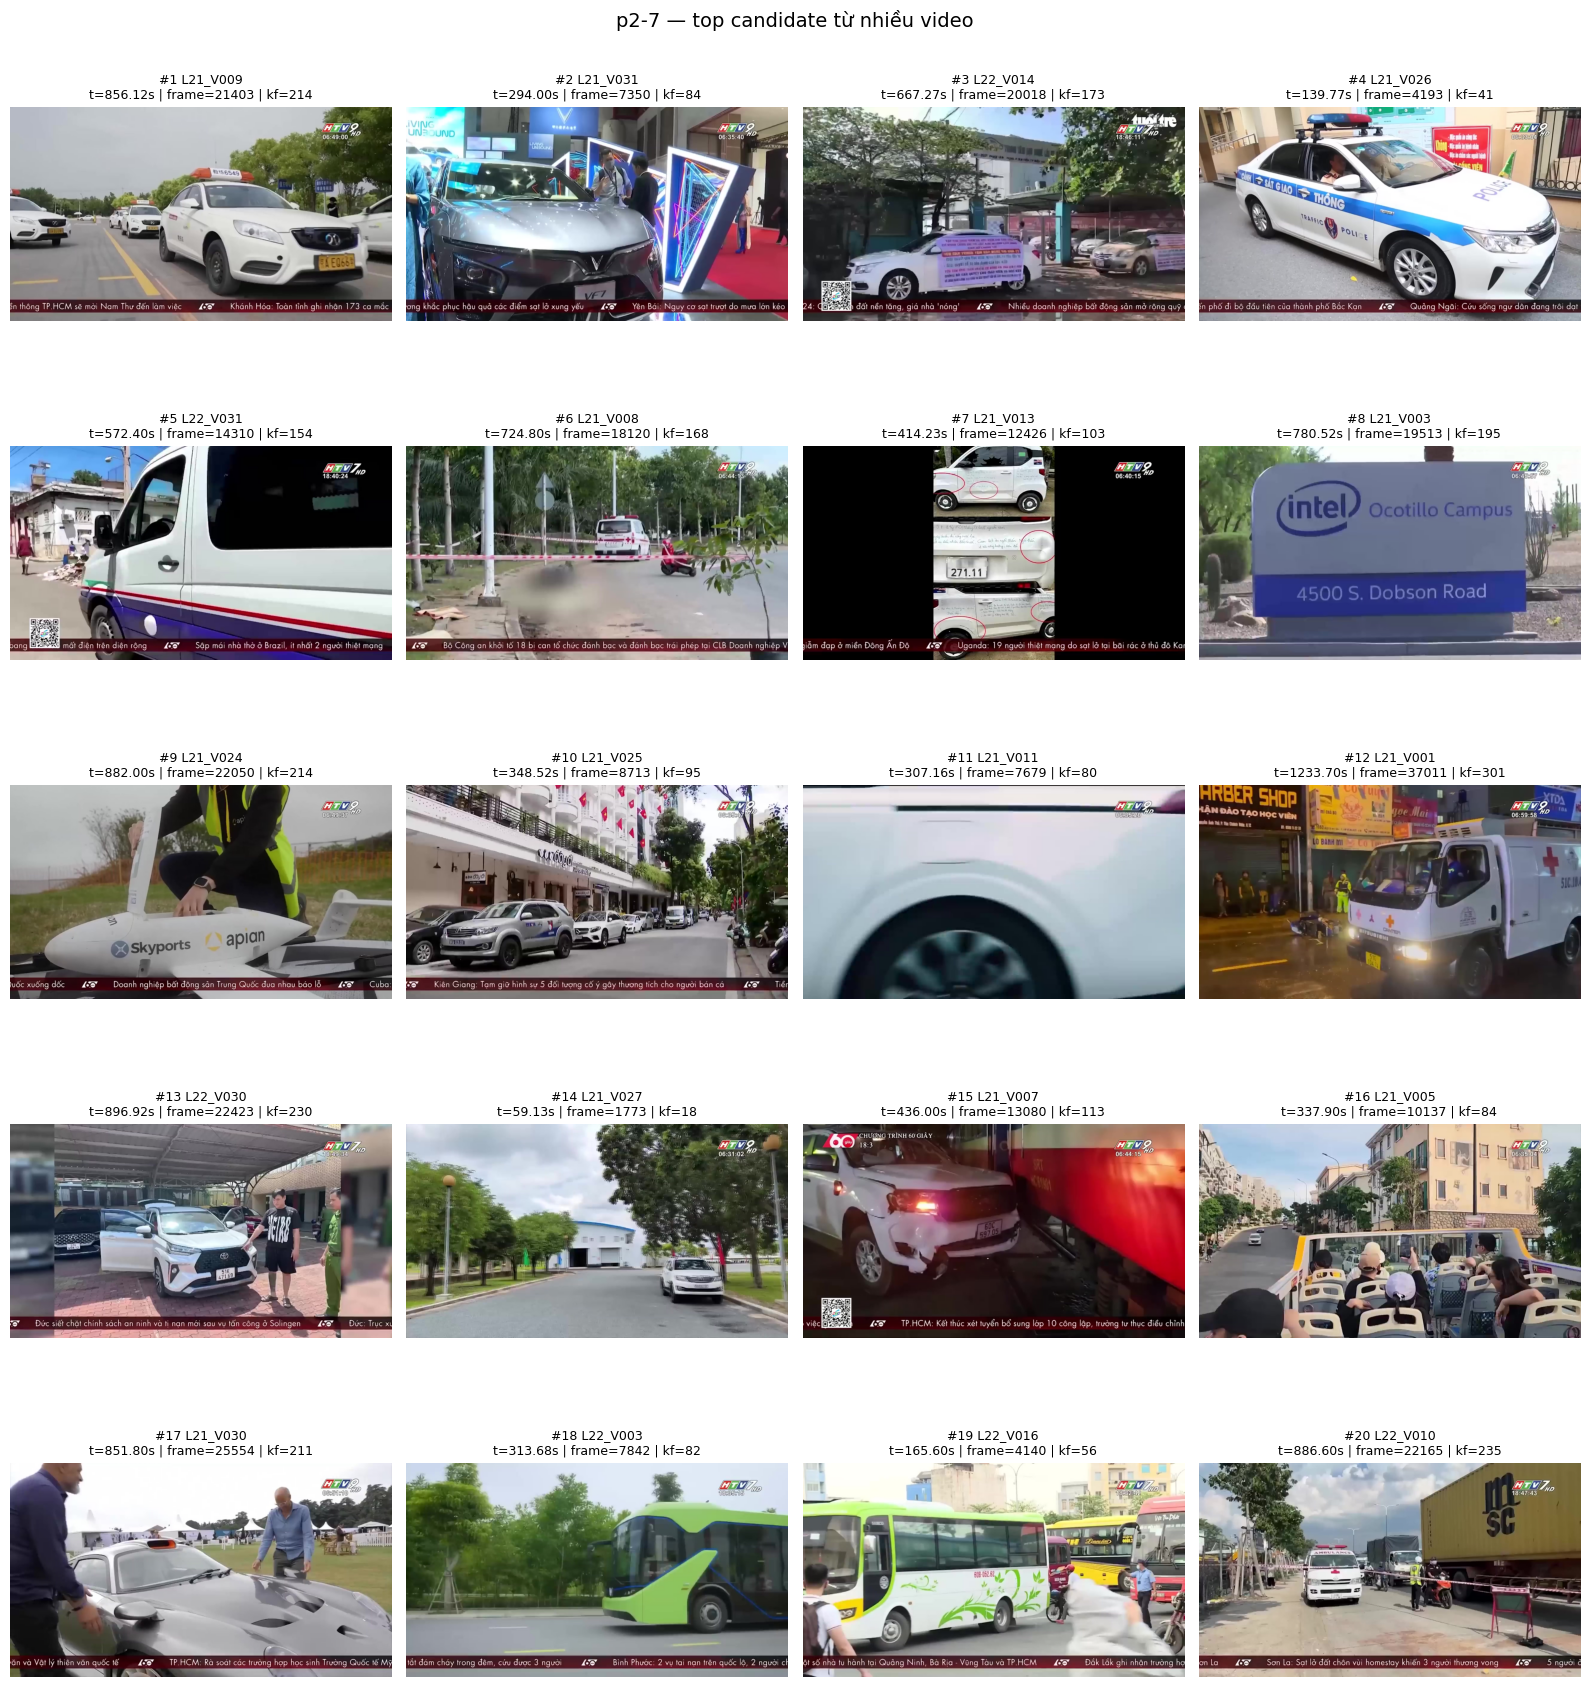

In [ ]:
# 13c) Đọc ảnh trực tiếp trong ZIP keyframe — không giải nén toàn bộ
from PIL import Image
import matplotlib.pyplot as plt

_KEYFRAME_LOCATOR = {}
_KEYFRAME_MEMBERS = {}
_KEYFRAME_ARCHIVES = {}

def open_keyframe_archive(zip_path):
    key = str(Path(zip_path).resolve())
    if key not in _KEYFRAME_ARCHIVES:
        _KEYFRAME_ARCHIVES[key] = zipfile.ZipFile(zip_path)
    return _KEYFRAME_ARCHIVES[key]

def natural_number(name):
    stem = Path(name).stem
    match = re.search(r'(\d+)$', stem)
    return int(match.group(1)) if match else 10**12

def locate_keyframe_zip(video_id):
    if video_id in _KEYFRAME_LOCATOR:
        return _KEYFRAME_LOCATOR[video_id]
    group = video_id.split('_', 1)[0]
    candidates = sorted(KEYFRAME_ZIP_DIR.glob(f'Keyframes_{group}*.zip'))
    if not candidates:
        raise FileNotFoundError(f'Không thấy ZIP keyframe cho {group} tại {KEYFRAME_ZIP_DIR}')
    pattern = re.compile(rf'(^|/){re.escape(video_id)}/', re.IGNORECASE)
    for zip_path in candidates:
        archive = open_keyframe_archive(zip_path)
        if any(pattern.search(name.replace('\\', '/')) for name in archive.namelist()):
            _KEYFRAME_LOCATOR[video_id] = zip_path
            return zip_path
    raise FileNotFoundError(f'Không tìm thấy thư mục {video_id} trong ZIP {group}.')

def members_for_video(video_id):
    if video_id in _KEYFRAME_MEMBERS:
        return _KEYFRAME_MEMBERS[video_id]
    zip_path = locate_keyframe_zip(video_id)
    pattern = re.compile(
        rf'(^|/){re.escape(video_id)}/[^/]+\.(jpg|jpeg|png)$', re.IGNORECASE
    )
    archive = open_keyframe_archive(zip_path)
    members = [
        name for name in archive.namelist()
        if pattern.search(name.replace('\\', '/'))
    ]
    members = sorted(members, key=lambda name: (natural_number(name), name))
    expected = int((frame_metadata['video_id'] == video_id).sum())
    if len(members) != expected:
        raise RuntimeError(f'{video_id}: ZIP có {len(members)} ảnh nhưng metadata có {expected} dòng.')
    _KEYFRAME_MEMBERS[video_id] = (zip_path, members)
    return zip_path, members

def load_keyframe_image(video_id, npy_row):
    zip_path, members = members_for_video(video_id)
    position = int(npy_row)
    if not 0 <= position < len(members):
        raise IndexError(f'{video_id}: npy_row {position} ngoài 0..{len(members)-1}')
    archive = open_keyframe_archive(zip_path)
    with archive.open(members[position]) as source:
        return Image.open(io.BytesIO(source.read())).convert('RGB')

def show_frame_table(table, max_images=20, columns=4, title='Keyframe candidates'):
    table = table.head(int(max_images)).reset_index(drop=True)
    if table.empty:
        print('Không có ảnh để hiển thị.')
        return
    rows = int(np.ceil(len(table) / int(columns)))
    fig, axes = plt.subplots(rows, int(columns), figsize=(4 * int(columns), 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, row in zip(axes, table.itertuples(index=False)):
        try:
            image = load_keyframe_image(row.video_id, row.npy_row)
            axis.imshow(image)
            axis.set_title(
                f'#{getattr(row, "rank", "?")} {row.video_id}\n'
                f't={float(row.pts_time):.2f}s | frame={int(row.frame_idx)} | kf={int(row.keyframe_n)}',
                fontsize=9,
            )
        except Exception as exc:
            axis.text(0.05, 0.5, f'{row.video_id}\n{exc}', wrap=True)
        axis.axis('off')
    for axis in axes[len(table):]:
        axis.axis('off')
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def show_query_contact_sheet(query_id, max_images=20, columns=4):
    result = BATCH_RESULTS[query_id]
    show_frame_table(
        result['frames'], max_images=max_images, columns=columns,
        title=f'{query_id} — top candidate từ nhiều video',
    )

def show_candidate_full(query_id, rank=1, crop=None):
    table = BATCH_RESULTS[query_id]['frames']
    row = table.iloc[int(rank) - 1]
    image = load_keyframe_image(str(row.video_id), int(row.npy_row))
    if crop is not None:
        image = image.crop(tuple(map(int, crop)))
    print({
        'query_id': query_id,
        'rank': int(rank),
        'video_id': str(row.video_id),
        'frame_idx': int(row.frame_idx),
        'pts_time': float(row.pts_time),
        'keyframe_n': int(row.keyframe_n),
        'title': str(row.title),
    })
    display(image)
    return image

def ocr_candidate(query_id, rank=1, crop=None, lang='vie+eng', psm=6):
    try:
        import pytesseract
    except ImportError:
        subprocess.run(['pip', 'install', '-q', 'pytesseract'], check=True)
        import pytesseract
    if shutil.which('tesseract') is None:
        subprocess.run(['apt-get', '-qq', 'update'], check=True)
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'tesseract-ocr', 'tesseract-ocr-vie'], check=True)
    image = show_candidate_full(query_id, rank=rank, crop=crop)
    text = pytesseract.image_to_string(image, lang=lang, config=f'--psm {int(psm)}')
    print('OCR:\n', text)
    return text

def show_video_timeline(video_id, start_seconds=None, end_seconds=None, every=1, max_images=60, columns=5):
    table = frame_metadata[frame_metadata['video_id'] == video_id].sort_values('frame_idx').copy()
    if start_seconds is not None:
        table = table[table['pts_time'] >= float(start_seconds)]
    if end_seconds is not None:
        table = table[table['pts_time'] <= float(end_seconds)]
    table = table.iloc[::max(1, int(every))].head(int(max_images)).copy()
    table.insert(0, 'rank', np.arange(1, len(table) + 1))
    show_frame_table(table, max_images=max_images, columns=columns, title=f'{video_id} timeline')
    return table

# Mặc định hiển thị ngay 20 ảnh của câu đang review.
try:
    show_query_contact_sheet(REVIEW_QUERY_ID, max_images=20, columns=4)
except Exception as exc:
    print('⚠ Chưa hiển thị được keyframe:', exc)
    print('Kiểm tra 14 ZIP tại:', KEYFRAME_ZIP_DIR)

# Ví dụ sau khi chọn được video:
# show_video_timeline('L25_V001', start_seconds=0, end_seconds=30, every=1)
# show_candidate_full('p2-29', rank=1)
# ocr_candidate('p2-29', rank=1)  # crop=(x1, y1, x2, y2) nếu chỉ OCR bảng


### 13d) Video chính thức cho QA/TRAKE

Chỉ gọi `download_official_video(video_id)` sau khi đã rút xuống 1–3 video ứng viên.


In [ ]:
# 13d) Tải CHỌN LỌC đúng một MP4 chính thức từ ZIP video qua HTTP Range
from remotezip import RemoteZip

VIDEO_ARCHIVES_BY_GROUP = {
    **{f'L{number}': [f'https://aic-data.ledo.io.vn/Videos_L{number}_a.zip'] for number in range(21, 31)},
    'L26': [f'https://aic-data.ledo.io.vn/Videos_L26_{part}.zip' for part in 'abcde'],
}
_REMOTE_VIDEO_LOCATOR = {}

def locate_official_video(video_id):
    if video_id in _REMOTE_VIDEO_LOCATOR:
        return _REMOTE_VIDEO_LOCATOR[video_id]
    group = video_id.split('_', 1)[0]
    urls = VIDEO_ARCHIVES_BY_GROUP.get(group, [])
    if not urls:
        raise KeyError(f'Không có archive cho group {group}')
    for url in urls:
        print('Kiểm tra central directory:', Path(url).name)
        with RemoteZip(url) as archive:
            members = [
                name for name in archive.namelist()
                if Path(name).stem.lower() == video_id.lower() and Path(name).suffix.lower() == '.mp4'
            ]
        if members:
            _REMOTE_VIDEO_LOCATOR[video_id] = (url, members[0])
            return url, members[0]
    raise FileNotFoundError(f'Không tìm thấy {video_id}.mp4 trong archive chính thức.')

def download_official_video(video_id, keep_on_drive=True):
    runtime_dir = WORK_DIR / 'selected_videos'
    runtime_dir.mkdir(parents=True, exist_ok=True)
    runtime_path = runtime_dir / f'{video_id}.mp4'
    drive_path = SELECTED_VIDEOS_DIR / f'{video_id}.mp4'
    if runtime_path.is_file() and runtime_path.stat().st_size > 0:
        return runtime_path
    if drive_path.is_file() and drive_path.stat().st_size > 0:
        print('→ Copy MP4 đã lưu trên Drive xuống runtime...')
        shutil.copy2(drive_path, runtime_path)
        return runtime_path
    url, member = locate_official_video(video_id)
    temporary = runtime_path.with_suffix('.mp4.part')
    print(f'↓ Trích riêng {member} từ {Path(url).name}...')
    with RemoteZip(url) as archive, archive.open(member) as source, open(temporary, 'wb') as output:
        shutil.copyfileobj(source, output, length=8 * 1024 * 1024)
    os.replace(temporary, runtime_path)
    if keep_on_drive:
        print('→ Lưu MP4 đã chọn lên Drive...')
        shutil.copy2(runtime_path, drive_path)
    print('✓', runtime_path, f'({runtime_path.stat().st_size / 2**20:.1f} MiB)')
    return runtime_path

def show_video_frame_window(video_id, center_frame, radius=60, step=10, columns=5):
    import cv2
    video_path = download_official_video(video_id)
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f'Không mở được {video_path}')
    total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_ids = list(range(
        max(0, int(center_frame) - int(radius)),
        min(total, int(center_frame) + int(radius) + 1),
        max(1, int(step)),
    ))
    images = []
    for frame_id in frame_ids:
        capture.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
        ok, bgr = capture.read()
        if ok:
            images.append((frame_id, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    capture.release()
    rows = int(np.ceil(len(images) / int(columns)))
    fig, axes = plt.subplots(rows, int(columns), figsize=(4 * int(columns), 3.3 * rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, (frame_id, image) in zip(axes, images):
        axis.imshow(image)
        axis.set_title(f'frame_idx={frame_id}')
        axis.axis('off')
    for axis in axes[len(images):]:
        axis.axis('off')
    plt.tight_layout()
    plt.show()
    return frame_ids

# Không tự tải video khi Run all. Sau khi chốt candidate, chạy ví dụ:
# path = download_official_video('L26_V001')
# show_video_frame_window('L26_V001', center_frame=12345, radius=90, step=10)
# Sau đó giảm step còn 2 hoặc 1 để chốt TRAKE.


## 14–15) Chốt đáp án và tạo submission P2

Điền 9 QA. Với một câu đã xác minh, ghi đúng một dòng vào `FINAL_ROWS_OVERRIDE`; dòng đó sẽ đứng top 1.


In [ ]:
# 14) CẤU HÌNH REVIEW P2 — chỉ điền giá trị đã nhìn thấy/xác nhận
QA_ANSWERS = {
    'p2-7': '1204',
    'p2-9': 'Cá Sòng',
    'p2-12': '7',
    'p2-19': 'Lý Thường Kiệt',
    'p2-23': '15',
    'p2-27': '2, 8',
    'p2-28': 'Cá Hồi',
    'p2-29': '200g',
    'p2-30': 'Ếch',
}

# Override một dòng ĐÃ XÁC MINH sẽ đưa đáp án đúng lên top 1 — tốt nhất theo cách chấm.
# Dùng frame_idx, tuyệt đối không dùng keyframe_n hay npy_row.
FINAL_ROWS_OVERRIDE = {
    # 'p2-1': [('L21_V003', 15240)],
    # 'p2-7': [('L21_V003', 15240, '42')],
    # 'p2-8': [('L21_V003', 100, 200, 300, 400)],
}

# Chỉ là fallback nếu chưa kịp dò video TRAKE chính xác.
USE_DRAFT_TRAKE_SEQUENCE = True

# Lần đầu để trống. Cell 15 sẽ in token sau khi đủ 9 đáp án QA.
FINAL_CONFIRMATION = 'FINALIZE-A382B40A1E29'


In [ ]:
# 15) Kiểm tra đúng 30 CSV P2 và đóng gói ZIP tách biệt khỏi P1
def rows_for_final_submission(query_id):
    if query_id in FINAL_ROWS_OVERRIDE:
        return FINAL_ROWS_OVERRIDE[query_id], 'VERIFIED_OVERRIDE'
    if query_id not in BATCH_RESULTS:
        raise KeyError('Không có batch candidate trong RAM; hãy chạy cell 13 trước.')
    task = QUERY_BANK[query_id]['task']
    result = BATCH_RESULTS[query_id]
    if task == 'kis':
        return result['frames'][['video_id', 'frame_idx']].head(100).copy(), 'HYBRID_UNVERIFIED'
    if task == 'qa':
        answer = str(QA_ANSWERS.get(query_id, '')).strip()
        if not answer:
            raise ValueError(f'{query_id}: chưa điền QA_ANSWERS.')
        rows = result['frames'][['video_id', 'frame_idx']].head(100).copy()
        rows['answer'] = answer
        return rows, 'HYBRID_FRAME_WITH_MANUAL_ANSWER'
    if not USE_DRAFT_TRAKE_SEQUENCE:
        raise ValueError(f'{query_id}: cần FINAL_ROWS_OVERRIDE hoặc bật draft TRAKE.')
    sequences = result['trake_sequences']
    if sequences is None or sequences.empty:
        raise ValueError(f'{query_id}: không có chuỗi TRAKE draft.')
    event_columns = [f'frame_{name}' for name in QUERY_BANK[query_id]['events_en']]
    return sequences[['video_id', *event_columns]].head(100).copy(), 'TRAKE_DRAFT_UNVERIFIED'

prepared_by_query = {}
finalization_problems = []
for query_id in QUERY_IDS_ORDERED:
    try:
        proposed_rows, row_source = rows_for_final_submission(query_id)
        task, cleaned_rows, expected_columns = prepare_submission_rows(query_id, proposed_rows)
        prepared_by_query[query_id] = {
            'task': task, 'rows': cleaned_rows, 'columns': expected_columns, 'source': row_source,
        }
    except Exception as error:
        finalization_problems.append({
            'query_id': query_id, 'problem': f'{type(error).__name__}: {error}',
        })

FINAL_SUBMISSION_ZIP = None
if finalization_problems:
    print('CHƯA TẠO ZIP — cần hoàn tất các mục sau:')
    display(pd.DataFrame(finalization_problems))
else:
    submission_payload = [
        {
            'query_id': query_id,
            'task': prepared_by_query[query_id]['task'],
            'rows': prepared_by_query[query_id]['rows'],
            'source': prepared_by_query[query_id]['source'],
        }
        for query_id in QUERY_IDS_ORDERED
    ]
    review_sha256 = hashlib.sha256(
        json.dumps(submission_payload, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode('utf-8')
    ).hexdigest()
    expected_confirmation = 'FINALIZE-' + review_sha256[:12].upper()
    review_table = pd.DataFrame([
        {
            'query_id': query_id,
            'task': prepared_by_query[query_id]['task'],
            'rows': len(prepared_by_query[query_id]['rows']),
            'source': prepared_by_query[query_id]['source'],
        }
        for query_id in QUERY_IDS_ORDERED
    ])
    display(review_table)
    print('Review SHA256:', review_sha256)
    if FINAL_CONFIRMATION != expected_confirmation:
        print('\nCHƯA TẠO ZIP. Sau khi bảng đúng, dán token này vào FINAL_CONFIRMATION:')
        print(expected_confirmation)
    else:
        build_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '-' + review_sha256[:12]
        local_build_dir = WORK_DIR / 'submission_builds_p2' / build_id
        local_submission_dir = local_build_dir / 'submission'
        local_submission_dir.mkdir(parents=True, exist_ok=False)
        expected_archive_names = []
        for query_id in QUERY_IDS_ORDERED:
            item = prepared_by_query[query_id]
            filename = f'query-{query_id}-{item["task"]}.csv'
            output_path = local_submission_dir / filename
            with open(output_path, 'w', encoding='utf-8', newline='') as file:
                csv.writer(file, delimiter=',', lineterminator='\n').writerows(item['rows'])
            validate_submission_file(query_id, output_path)
            expected_archive_names.append(f'submission/{filename}')

        local_zip = local_build_dir / 'submission.zip'
        with zipfile.ZipFile(local_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
            for query_id in QUERY_IDS_ORDERED:
                item = prepared_by_query[query_id]
                filename = f'query-{query_id}-{item["task"]}.csv'
                archive.write(local_submission_dir / filename, arcname=f'submission/{filename}')
        with zipfile.ZipFile(local_zip) as archive:
            if archive.namelist() != expected_archive_names:
                raise RuntimeError('Tên/thứ tự file trong ZIP P2 không đúng.')
            if archive.testzip() is not None:
                raise RuntimeError('ZIP submission P2 bị lỗi CRC.')
            for query_id, archive_name in zip(QUERY_IDS_ORDERED, expected_archive_names):
                rows = list(csv.reader(io.StringIO(archive.read(archive_name).decode('utf-8'))))
                prepare_submission_rows(query_id, rows)

        final_dir = P2_SUBMISSION_ROOT / 'final'
        final_dir.mkdir(parents=True, exist_ok=True)
        drive_zip = final_dir / f'submission_p2_{build_id}.zip'
        drive_manifest = final_dir / f'submission_p2_{build_id}.manifest.json'
        shutil.copy2(local_zip, drive_zip)
        if sha256_file(local_zip) != sha256_file(drive_zip):
            raise RuntimeError('Checksum ZIP P2 trên Drive không khớp runtime.')
        final_manifest = {
            'build_id': build_id,
            'created_at_utc': datetime.now(timezone.utc).isoformat(),
            'batch_run_id': BATCH_RUN_ID,
            'review_sha256': review_sha256,
            'zip_sha256': sha256_file(drive_zip),
            'zip_path': str(drive_zip),
            'files': expected_archive_names,
            'rows': submission_payload,
        }
        with open(drive_manifest, 'w', encoding='utf-8', newline='\n') as file:
            json.dump(final_manifest, file, ensure_ascii=False, indent=2)
        FINAL_SUBMISSION_ZIP = drive_zip
        print('\nFINAL P2 SUBMISSION CREATED')
        print('ZIP:', drive_zip)
        print('SHA256:', final_manifest['zip_sha256'])
        print('Gồm đúng 30 CSV, không header, nằm trong thư mục submission/ của ZIP.')


,query_id,task,rows,source
0,p2-1,kis,100,HYBRID_UNVERIFIED
1,p2-2,kis,100,HYBRID_UNVERIFIED
2,p2-3,kis,100,HYBRID_UNVERIFIED
3,p2-4,kis,100,HYBRID_UNVERIFIED
4,p2-5,kis,100,HYBRID_UNVERIFIED
5,p2-6,kis,100,HYBRID_UNVERIFIED
6,p2-7,qa,100,HYBRID_FRAME_WITH_MANUAL_ANSWER
7,p2-8,trake,25,TRAKE_DRAFT_UNVERIFIED
8,p2-9,qa,100,HYBRID_FRAME_WITH_MANUAL_ANSWER
9,p2-10,kis,100,HYBRID_UNVERIFIED


Review SHA256: a382b40a1e2909029c9a58f193ad8a8d04327596b909061e8f9744f86c2c00f5

FINAL P2 SUBMISSION CREATED
ZIP: /content/drive/MyDrive/AIC2026/submission/p2/final/submission_p2_20260828T151553786332Z-a382b40a1e29.zip
SHA256: ed44bebfeae30ea63ab485787ff3f4299689646fa63c6d70c690cbd9795898ac
Gồm đúng 30 CSV, không header, nằm trong thư mục submission/ của ZIP.


## Thứ tự làm nhanh

1. Review QA dễ đọc chữ/đếm: p2-7, p2-12, p2-23, p2-27, p2-29.
2. Review QA nhận diện: p2-9, p2-28, p2-30; sau đó p2-19.
3. Chốt các KIS có hình rất đặc trưng và đưa một dòng verified lên top 1.
4. TRAKE: tìm đúng video bằng draft, tải MP4 chính thức, rà frame với `show_video_frame_window`.
5. Điền token và nộp file trong `MyDrive/AIC2026/submission/p2/final/`.
